In [136]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import statsmodels.api as sm
import yaml
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

sys.path.insert(0, str(Path.cwd().parent))

from utils.fast_OLS import DiagnosticoOLS
from utils.geo import add_landmark_distances
from utils.map_graph import create_map, show_map
from utils.pca_plots import plot_loadings, plot_ppca_matrices, plot_scree
from utils.triple_plot import normality_report
from utils.vif_resume import vif_table

sklearn.set_config(transform_output="pandas")

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
GEO_DIR = ROOT_DIR / "geodata"

In [137]:
df = pd.read_csv(DATA_DIR / "datos_inmobiliarios_ready.csv")

In [138]:
bogota_marks_yaml_path = GEO_DIR / "bogota_landmarks.yaml"
with open(bogota_marks_yaml_path, "r", encoding="utf-8") as file:
    geo_data = yaml.safe_load(file)

In [139]:
df.columns

Index(['price_amount', 'admin_fee', 'area_built_m2', 'bedrooms', 'bathrooms',
       'parking_spaces', 'stratum', 'floor', 'age_bracket_code', 'latitude',
       'longitude', 'Trans Publico cerc', 'Zona Residencial', 'n_amenities',
       'construction_state_grouped_A estrenar',
       'construction_state_grouped_Buen estado',
       'construction_state_grouped_Excelente estado',
       'construction_state_grouped_Otros', 'city_Chía', 'city_Soacha',
       'city_Zipaquirá', 'locality_frec', 'neighborhood_grouped_frec',
       'publisher_type_desarrollador', 'publisher_type_inmobiliaria',
       'property_type_apartaestudio', 'property_type_casa',
       'property_type_casa_campestre', 'property_type_finca',
       'property_type_habitacion', 'meses_ofertado'],
      dtype='str')

# Generar variables de distancia a `landmarks` positivos y negativos

Un landmark positivo es un factor que se cree será de plusvalía para el inmueble, mientras que uno negativo se espera suponga una reducción en el precio de este. Las siguientes variables se basan en mostrar la distancia de cada vivienda a su landmark de cada tipo más cercano.

In [140]:
positive_landmarks = geo_data.get("positive_landmarks", {})
negative_landmarks = geo_data.get("negative_landmarks", {})

df_pos = pd.DataFrame.from_dict(positive_landmarks, orient="index").assign(
    label="positive"
)
df_neg = pd.DataFrame.from_dict(negative_landmarks, orient="index").assign(
    label="negative"
)
df_landmarks = pd.concat([df_pos, df_neg])
df_landmarks = df_landmarks.reset_index().rename(
    columns={"index": "landmark_name"}
)

In [141]:
show_map(
    create_map(
        df_landmarks,
        name_col="landmark_name",
        label_col="label",
        colors={"positive": "green", "negative": "red"},
        cluster=False,
    )
)

In [142]:
df = add_landmark_distances(df_houses=df, df_landmarks=df_landmarks)

# Seleccionar variables continuas a usar

Se van a utilizar variables que son en sí continuas, y por falta de variables puramente continuas se van a tomar las variables numéricas discretas con varios valores posibles como continuas. Esto se ve sustentado en que, con rangos amplios, las variables discretas presentan un comportamiento similar a una continua.

In [143]:
numeric_purpoused_cols = [
    "price_amount",
    "admin_fee",
    "latitude",
    "longitude",
    "locality_frec",
    "n_amenities",
    "neighborhood_grouped_frec",
    "dist_nearest_positive_km",
    "dist_nearest_negative_km",
    "area_built_m2",
]

numeric_pca_cols = []

for col in numeric_purpoused_cols:
    n_unique = df[col].nunique()
    if n_unique >= 10:
        print(
            f"La columna {col} tiene {n_unique} valores unicos, "
            "se puede usar en PCA"
        )
        numeric_pca_cols.append(col)
    else:
        print(f"La columna {col} tiene {n_unique} valores unicos, NO SE USA")
    print("-" * 85, "\n")

La columna price_amount tiene 1638 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna admin_fee tiene 9244 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna latitude tiene 16126 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna longitude tiene 15913 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna locality_frec tiene 19 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna n_amenities tiene 65 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna neighborhood_grouped_frec tiene 20 valore

In [144]:
len(numeric_pca_cols)

10

# Analizar escalas

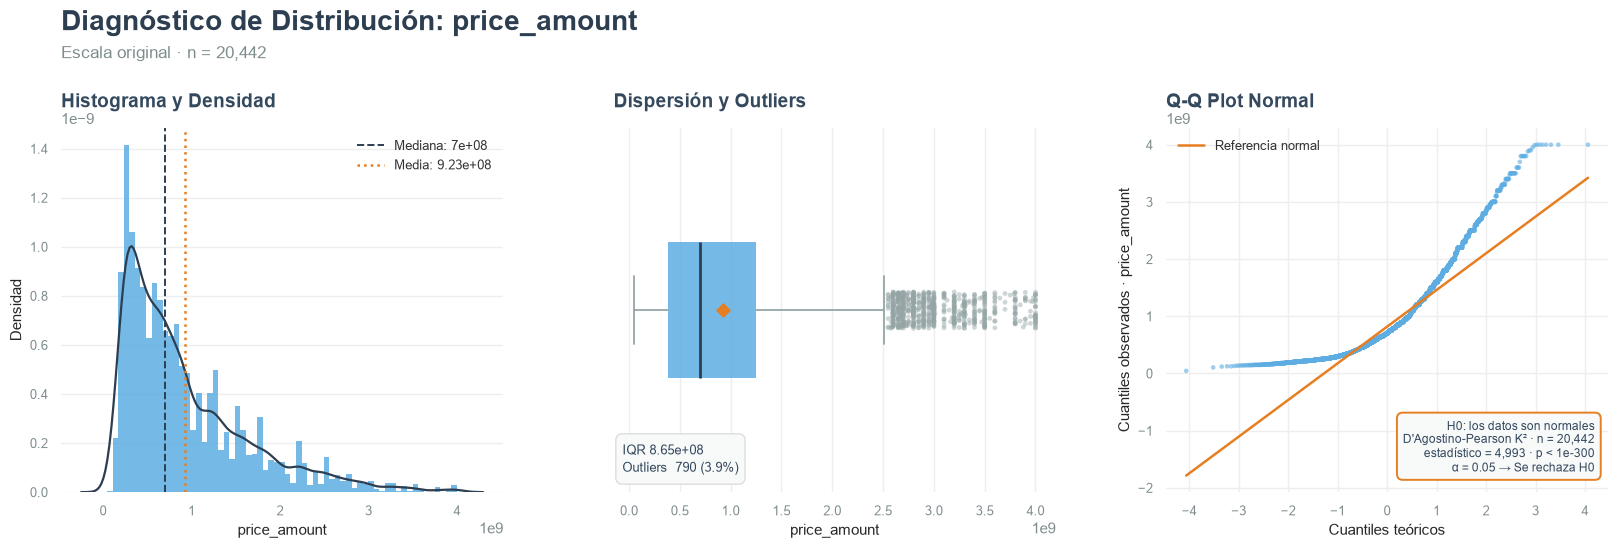

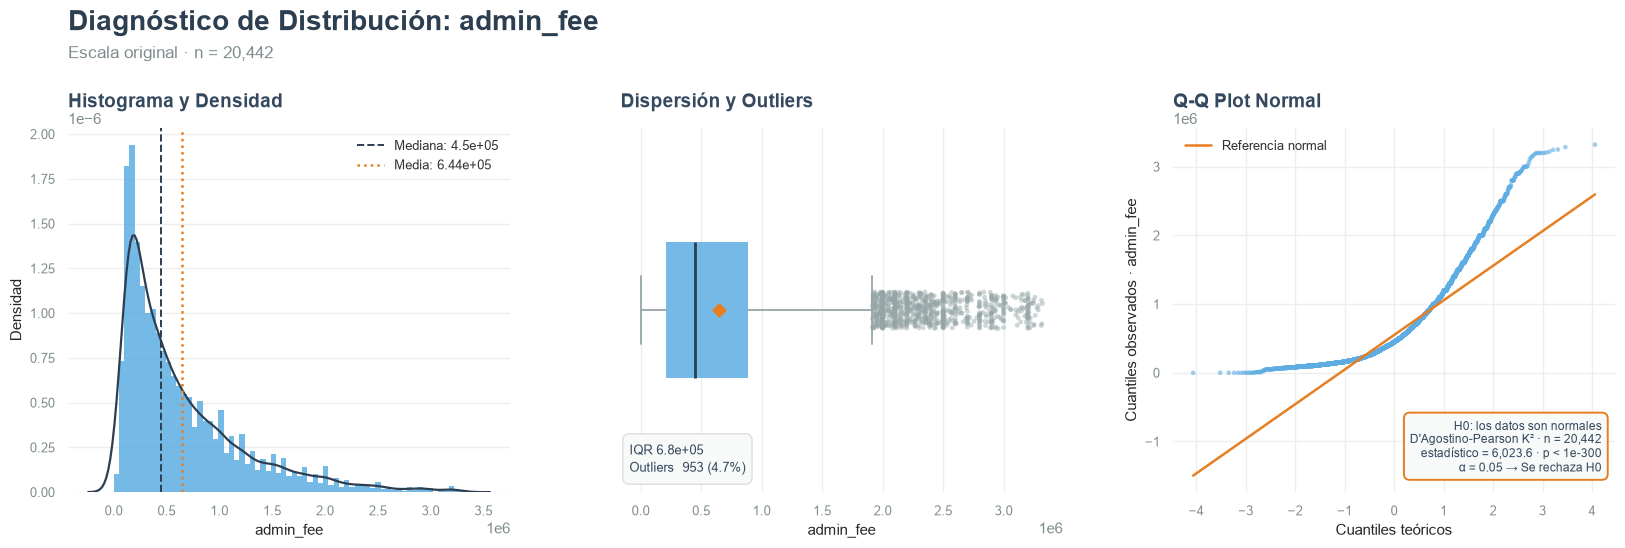

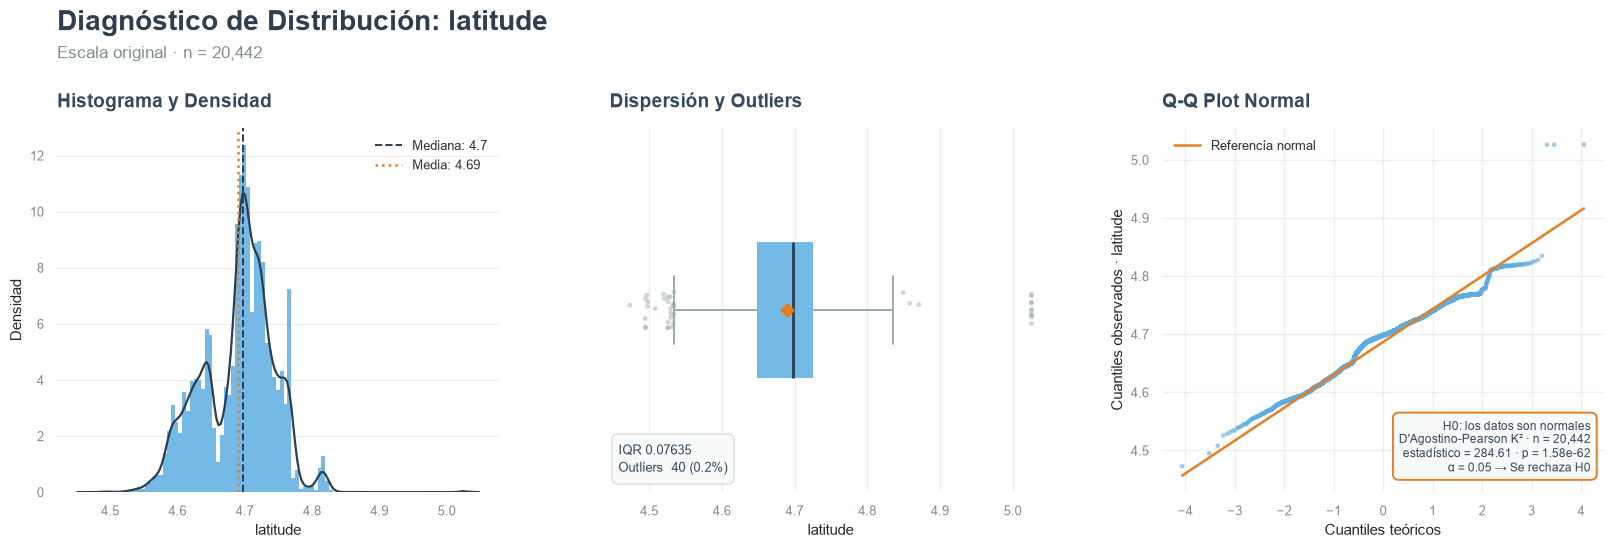

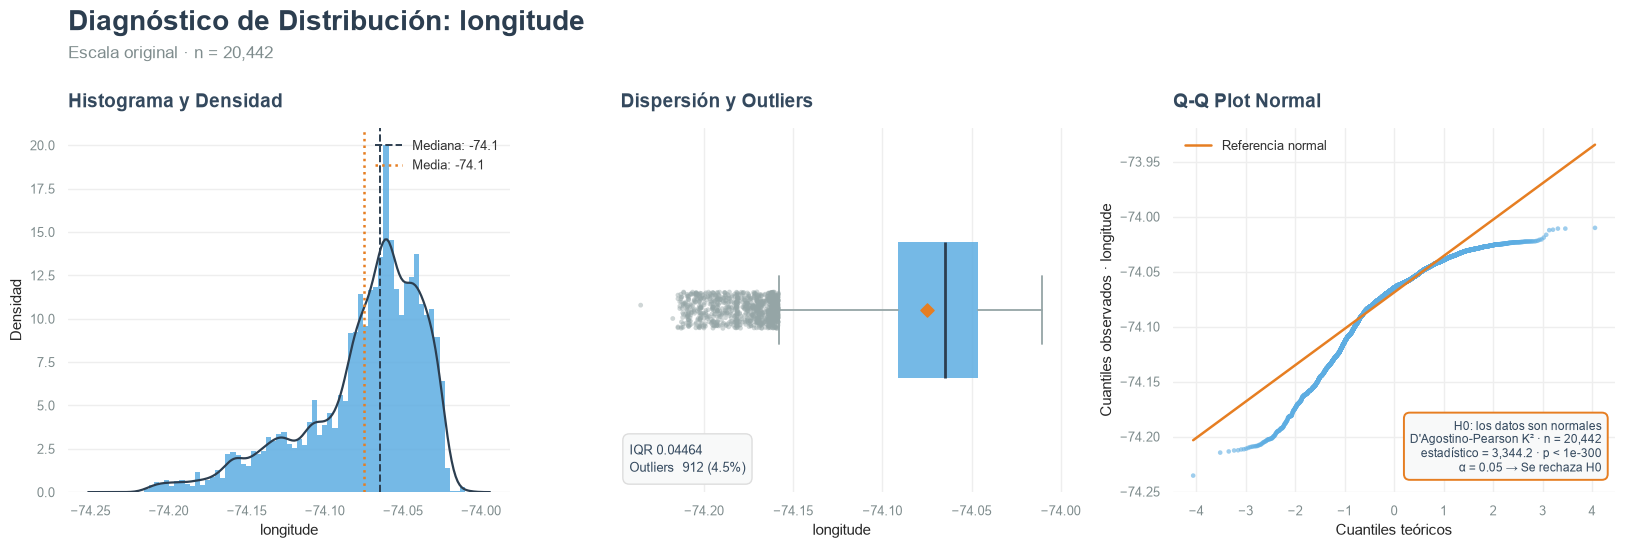

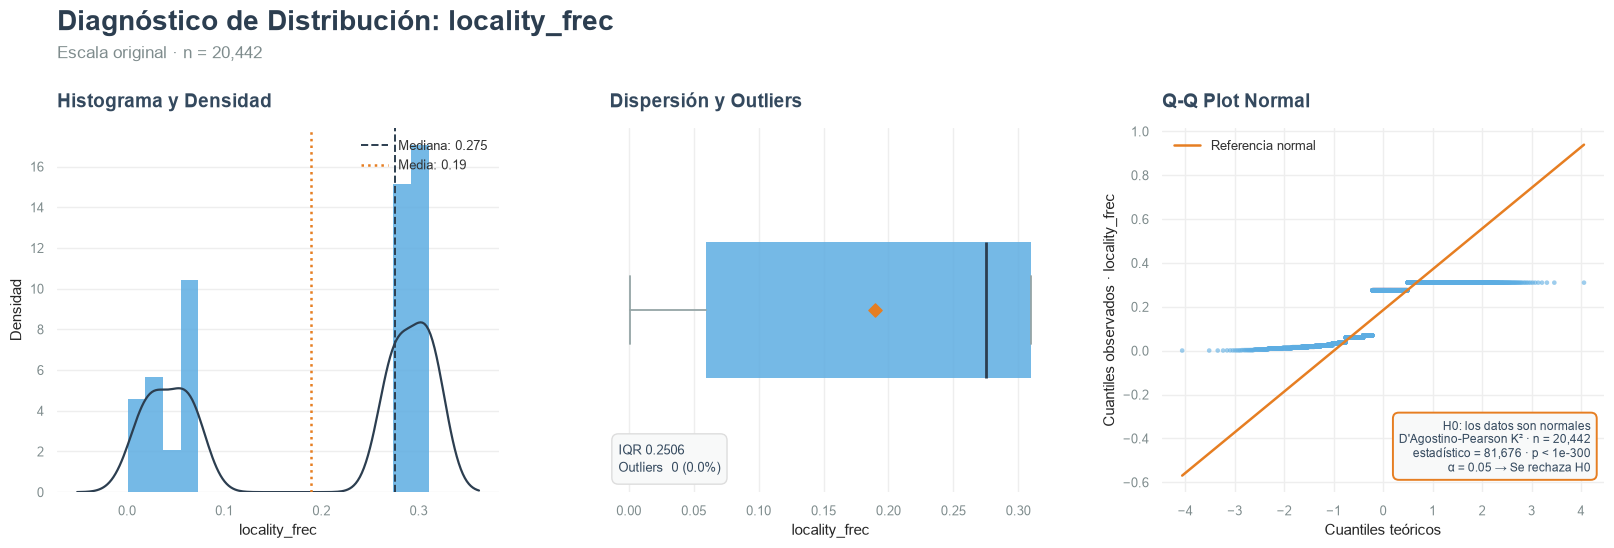

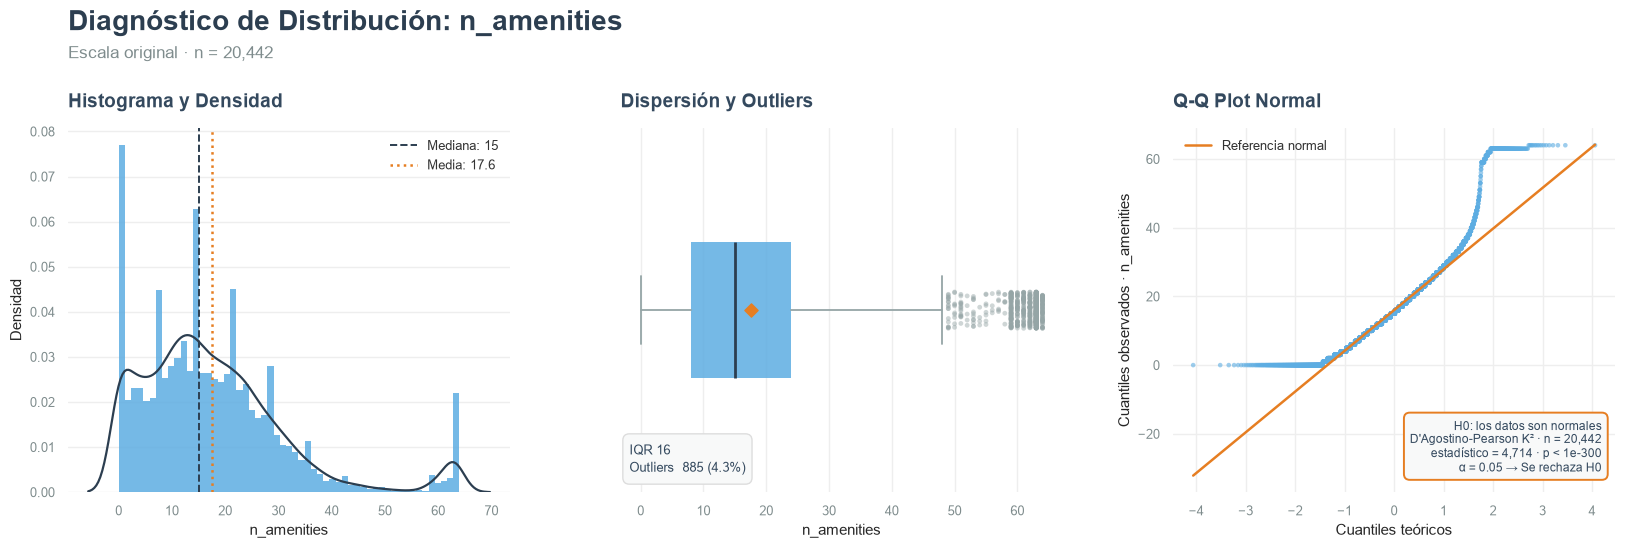

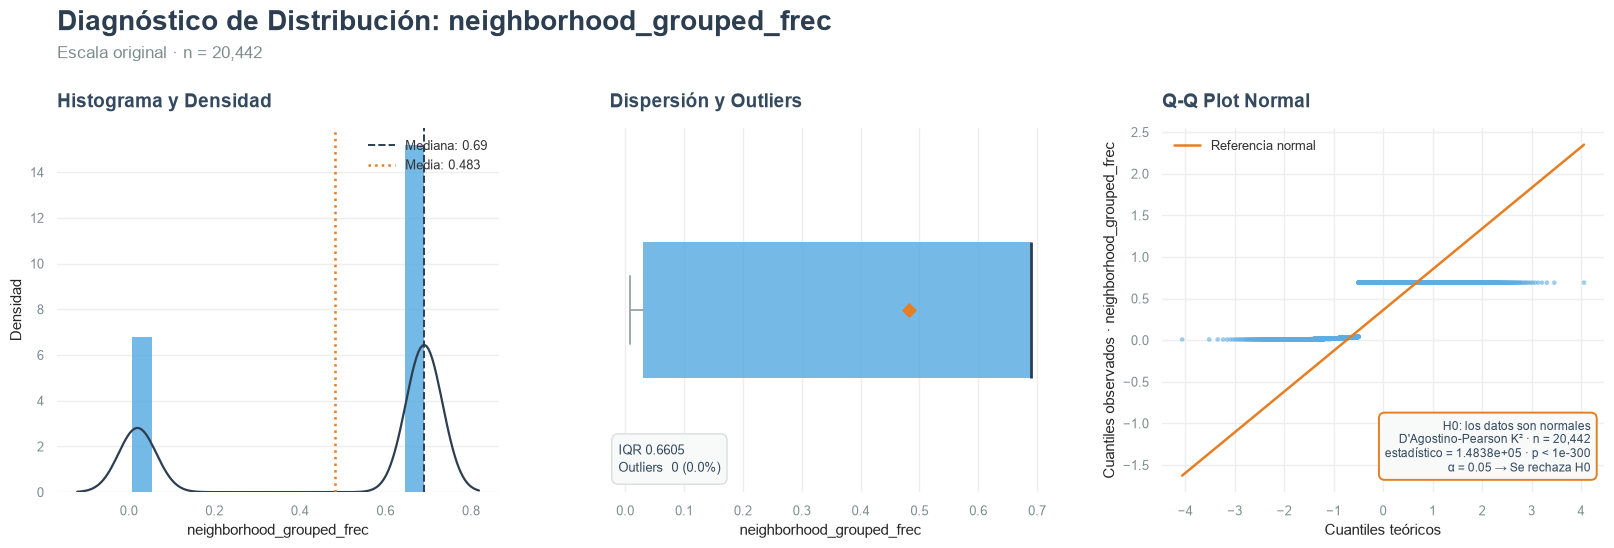

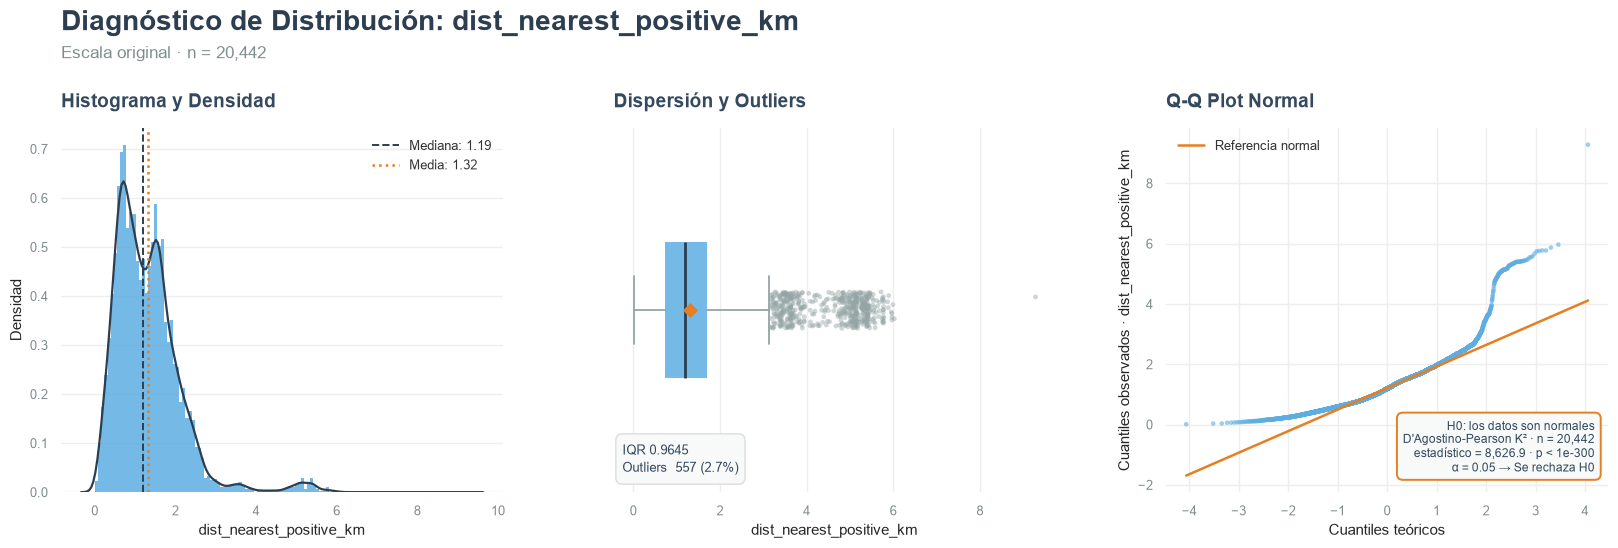

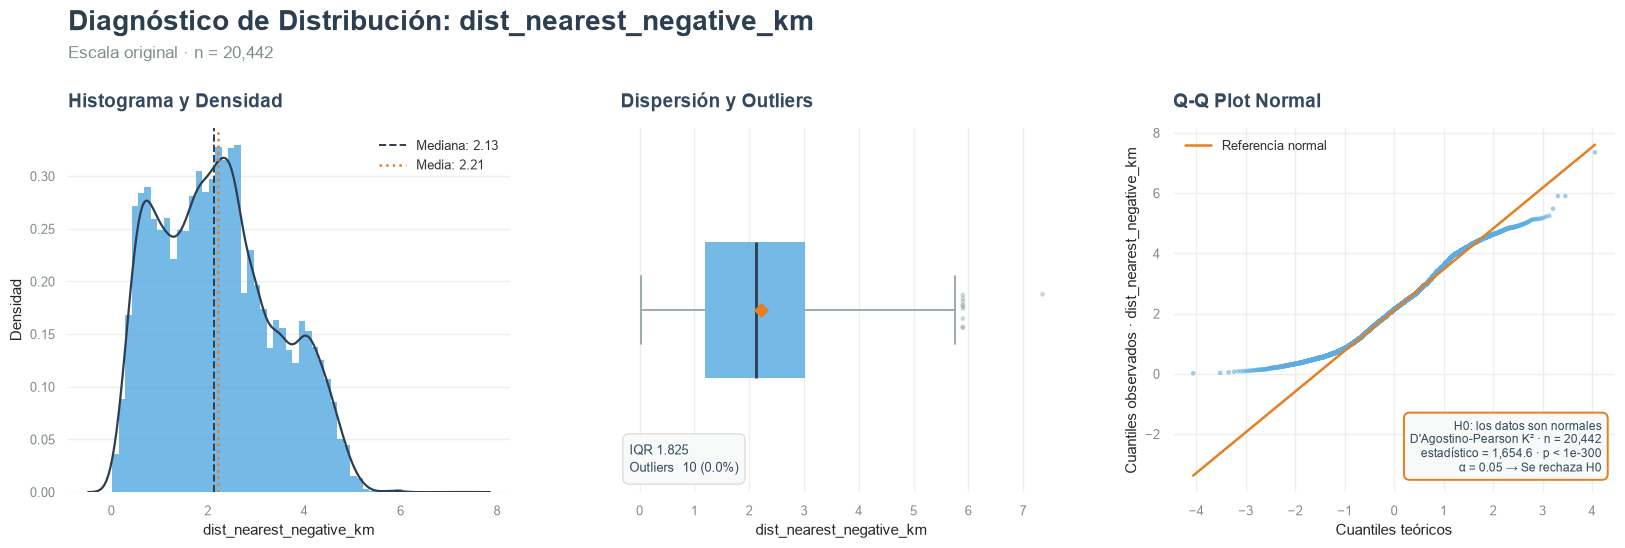

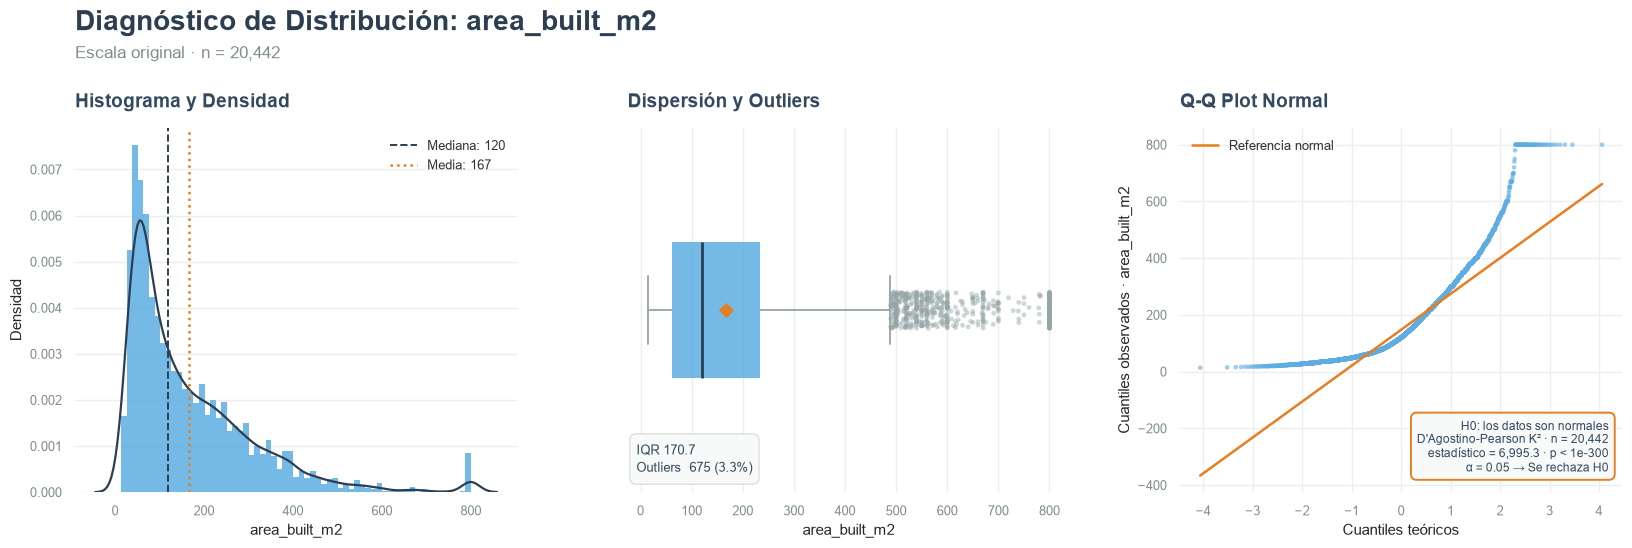

In [145]:
for col in numeric_pca_cols:
    normality_report(df, col)

Note que múltiples variables tienen sesgo a la derecha; luego, la media podría no representar el centro de los datos y no hacer efectivo el paso de centrar los datos en el origen geométrico. Por lo tanto, se van a probar 2 enfoques. El primero consta de estandarizar las variables tal como están, ver cómo se comportan sus componentes y qué tanto es el error de reconstrucción, y el segundo consta de primero aplicar transformaciones como logaritmos, esto con el fin de aproximar las variables a una campana, y después estandarizar.

> Note que siempre se plantea la estandarización; esto se hace ya que las variables están en escalas muy dispares, por ejemplo, se tienen proporciones y precios en COP.

# Aplicar PCA 

A continuación se mostrarán 2 formas de enfocar PCA: uno descriptivo, donde se usarán todas las variables para identificar las direcciones de mayor variabilidad e interpretar los loadings de las direcciones, y un enfoque dirigido al preprocesamiento de datos, donde se excluirá la variable `price_amount`. Después se seleccionarán componentes tales que expliquen por lo menos el 80% de la variabilidad en menos dimensionalidad, para posteriormente interpretar los loadings y ajustar una regresión lineal con este nuevo conjunto. Se comparará el rendimiento de esta regresión con la ejecutada en el cuaderno `notebooks/model_OLS.ipynb`.

## Usando todo el set

### Usando las variables originales (estandarizadas)


In [146]:
df_pca = df[numeric_pca_cols].copy()

In [147]:
df_pca_std = StandardScaler().fit_transform(df_pca)

In [148]:
df_pca_std.describe()  # los datos estan centrados y en media 0, aunque el
# numero no es exactamente 0 es valido pues es una de las propiedades de
# StandardScaler

,price_amount,admin_fee,latitude,longitude,locality_frec,n_amenities,neighborhood_grouped_frec,dist_nearest_positive_km,dist_nearest_negative_km,area_built_m2
count,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04
mean,1.112287e-16,-1.334744e-16,1.084480e-16,-1.575221e-13,2.502645e-17,-1.279130e-16,1.724045e-16,-1.112287e-16,-2.085538e-16,-8.898295e-17
std,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00
min,-1.240646e+00,-1.107874e+00,-4.082441e+00,-4.170268e+00,-1.504465e+00,-1.271803e+00,-1.534401e+00,-1.571186e+00,-1.810379e+00,-1.080784e+00
25%,-7.605389e-01,-7.464108e-01,-7.849832e-01,-4.270008e-01,-1.035203e+00,-6.921312e-01,-1.462249e+00,-7.081365e-01,-8.318795e-01,-7.411921e-01
50%,-3.149048e-01,-3.333085e-01,1.501185e-01,2.612787e-01,6.847750e-01,-1.849188e-01,6.694747e-01,-1.531854e-01,-6.114816e-02,-3.308518e-01
75%,4.631866e-01,4.240457e-01,6.511599e-01,7.315962e-01,9.614993e-01,4.672115e-01,6.694747e-01,4.522404e-01,6.788945e-01,4.667740e-01
max,4.353643e+00,4.608201e+00,6.316570e+00,1.676758e+00,9.614993e-01,3.365568e+00,6.694747e-01,9.585711e+00,4.260418e+00,4.480034e+00


In [149]:
pca_org = PCA()

In [150]:
df_pca = pca_org.fit_transform(df_pca_std)

In [151]:
pca_org.explained_variance_ratio_ * 100

array([37.18067075, 15.58585219, 12.65372816,  9.51251382,  7.82874191,
        6.6335021 ,  5.28504594,  2.61727101,  1.40430875,  1.29836535])

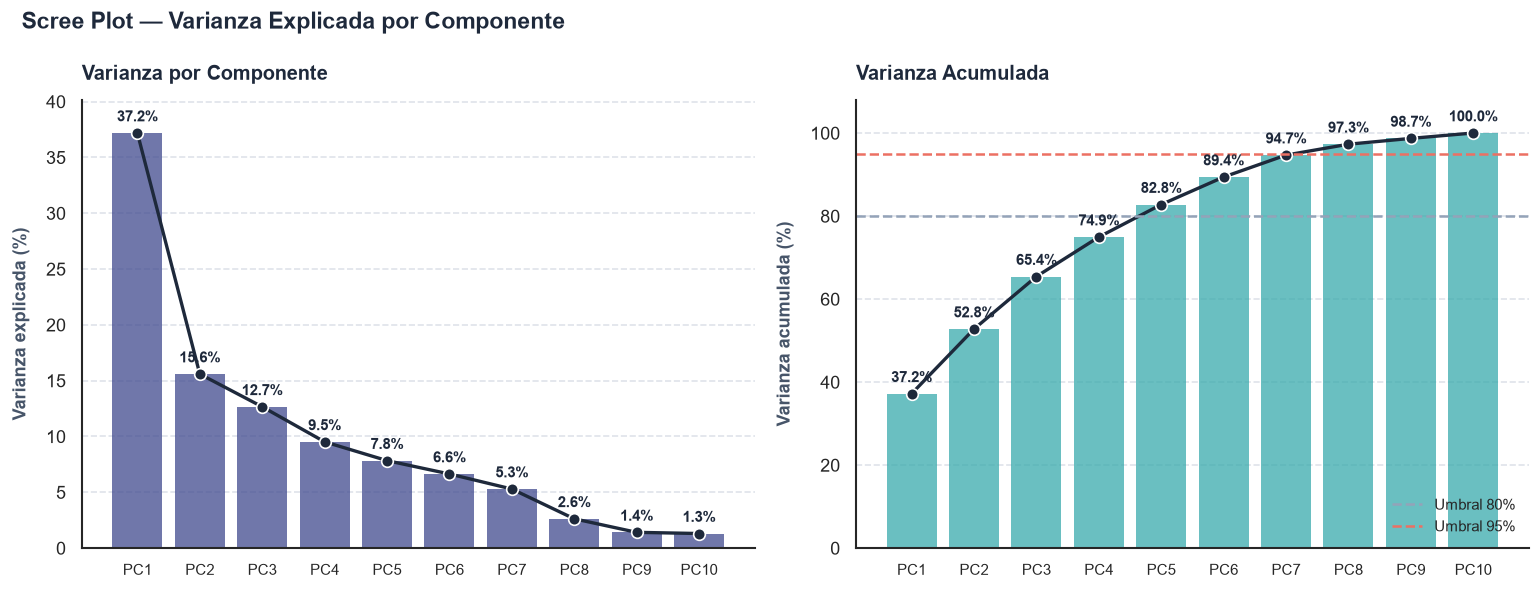

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



(<Figure size 1560x600 with 2 Axes>,
 array([<Axes: title={'left': 'Varianza por Componente'}, ylabel='Varianza explicada (%)'>,
        <Axes: title={'left': 'Varianza Acumulada'}, ylabel='Varianza acumulada (%)'>],
       dtype=object))

In [152]:
plot_scree(pca_org)

Vea que con 5 componentes se obtiene una varianza explicada del 84.5%; ahora se da paso a interpretar sus cargas.

In [153]:
pca_org_5 = PCA(n_components=5)
df_pca_5 = pca_org_5.fit_transform(df_pca_std)

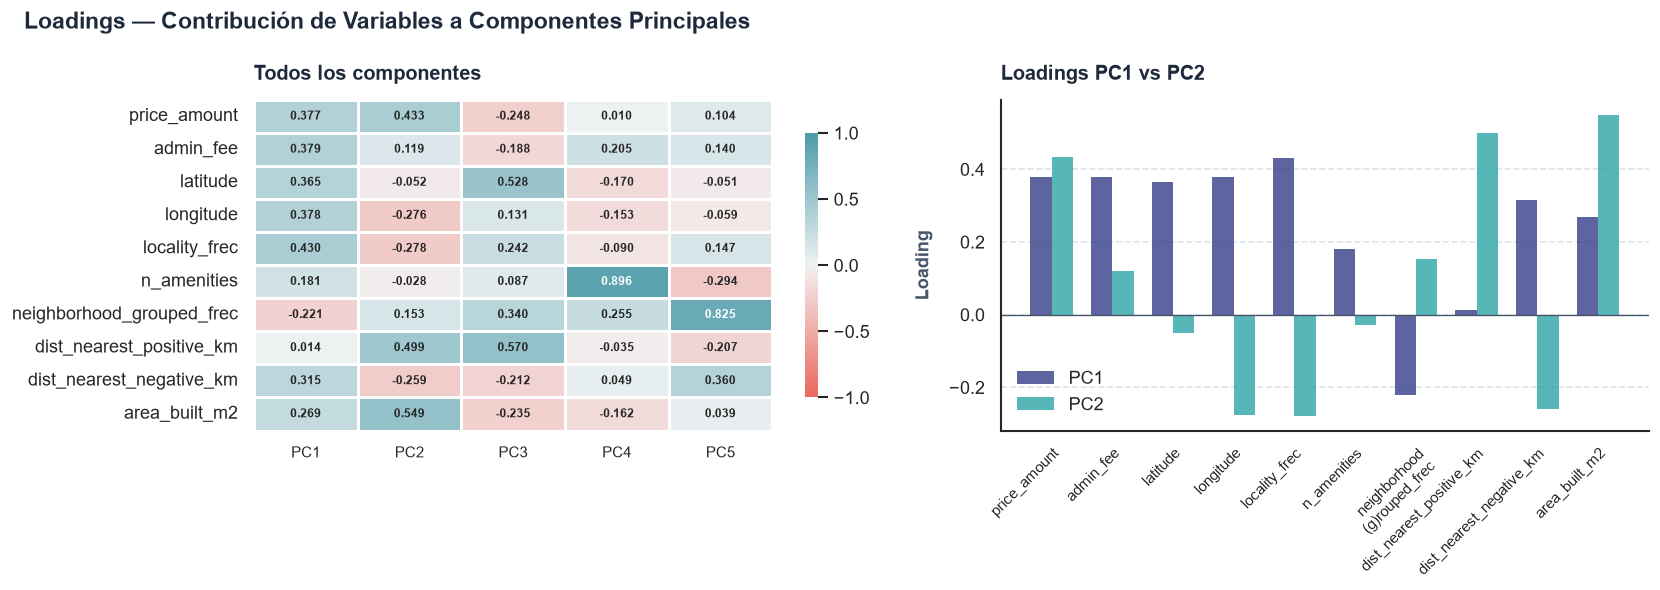

In [154]:
out = plot_loadings(pca_org_5, numeric_pca_cols)

La primera componente combina características económicas y geográficas de los inmuebles, describiendo viviendas con precios, cuotas de administración y tamaños elevados relacionados con su ubicación. Mientras que PC2 representa a viviendas alejadas de landmarks positivos y cercanas a puntos negativos, con una consideración mayor del tamaño del inmueble.

Por otro lado, la tercera componente describe viviendas económicas, con administración baja y PC4 viviendas con muchas amenidades, ubicadas en barrios más frecuentes en la muestra.

Por último, PC5 representa viviendas en barrios más frecuentes, con menos amenidades y alejadas de landmarks negativos.

In [155]:
df_rec_org = pca_org_5.inverse_transform(df_pca_5)

In [156]:
df_rec_org

array([[ 0.0870811 ,  0.43203801,  0.43507767, ..., -0.22743932,
         0.68095423, -0.22550651],
       [-0.4166791 , -0.74669992, -0.29818781, ...,  0.74278197,
        -0.92031092, -0.04210614],
       [-0.40250392,  0.19226385,  0.82189976, ..., -0.27599968,
         0.68925765, -0.76732433],
       ...,
       [-0.4954917 , -0.16106269, -0.90601078, ..., -0.11507356,
        -0.42058254, -0.64621113],
       [-0.94314958, -0.68937914,  0.92858226, ...,  0.15548579,
         0.13840757, -0.8684225 ],
       [-0.93071503, -0.55744917,  1.09269638, ...,  1.0804609 ,
        -0.56705438, -0.98289537]], shape=(20442, 10))

In [157]:
mse_error_org = np.mean((df_pca_std - df_rec_org) ** 2)

print(f"Error de reconstrucción promedio (MSE): {mse_error_org}")

Error de reconstrucción promedio (MSE): 0.17238493161401314


In [158]:
# Error cuadrático por variable (columnas)
mse_por_variable = np.mean((df_pca_std - df_rec_org) ** 2, axis=0)

# Si df_pca_std es un DataFrame, puedes presentarlo como Series
error_variables = pd.Series(mse_por_variable, index=df_pca_std.columns)
print("Error de reconstrucción por variable:")
display(error_variables.sort_values())

Error de reconstrucción por variable:


n_amenities                  0.036212
neighborhood_grouped_frec    0.039802
price_amount                 0.092532
locality_frec                0.095071
latitude                     0.117106
dist_nearest_positive_km     0.165147
area_built_m2                0.165302
longitude                    0.303854
admin_fee                    0.343141
dist_nearest_negative_km     0.365683
dtype: float64

In [159]:
mse_por_variable

price_amount                 0.092532
admin_fee                    0.343141
latitude                     0.117106
longitude                    0.303854
locality_frec                0.095071
n_amenities                  0.036212
neighborhood_grouped_frec    0.039802
dist_nearest_positive_km     0.165147
dist_nearest_negative_km     0.365683
area_built_m2                0.165302
dtype: float64

### Usando las variables transformadas (estandarizadas)


In [160]:
df_features_pca = df[numeric_pca_cols].copy()
df_features_pca.min() <= 0

price_amount                 False
admin_fee                    False
latitude                     False
longitude                     True
locality_frec                False
n_amenities                   True
neighborhood_grouped_frec    False
dist_nearest_positive_km     False
dist_nearest_negative_km     False
area_built_m2                False
dtype: bool

In [161]:
biased_cols = [
    "price_amount",
    "admin_fee",
    "latitude",
    "longitude",
    "n_amenities",
    "dist_nearest_positive_km",
    "dist_nearest_negative_km",
    "area_built_m2",
]

for col in biased_cols:
    if col == "longitude":
        min_val = df_features_pca[col].min()
        shift = abs(min_val) + 1 if min_val < 0 else 0

        df_features_pca[f"{col}_log"] = np.log(df_features_pca[col] + shift)
    else:
        df_features_pca[f"{col}_log"] = np.log1p(df_features_pca[col])

    df_features_pca.drop(columns=[col], inplace=True)

In [162]:
len(df_features_pca.columns)

10

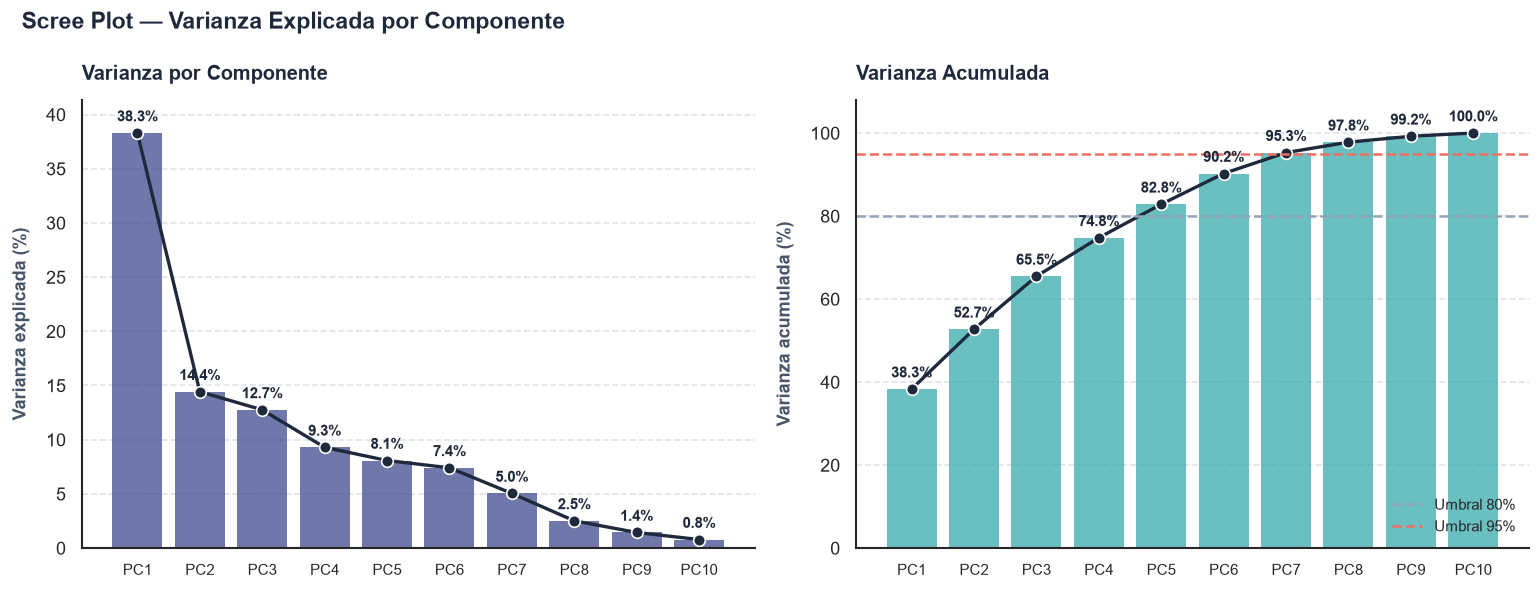

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



(<Figure size 1560x600 with 2 Axes>,
 array([<Axes: title={'left': 'Varianza por Componente'}, ylabel='Varianza explicada (%)'>,
        <Axes: title={'left': 'Varianza Acumulada'}, ylabel='Varianza acumulada (%)'>],
       dtype=object))

In [163]:
pca_org_trans = PCA()
df_features_pca_std = StandardScaler().fit_transform(df_features_pca)
df_pca_trans = pca_org_trans.fit_transform(df_features_pca_std)
plot_scree(pca_org_trans)

Note que con 5 componentes ahora está explicando menos variabilidad, por lo que se podría pensar que, en principio, el modelo empeoró con esta transformación.

In [164]:
pca_org_trans_5 = PCA(n_components=5)
df_pca_5_trans = pca_org_trans_5.fit_transform(df_features_pca_std)

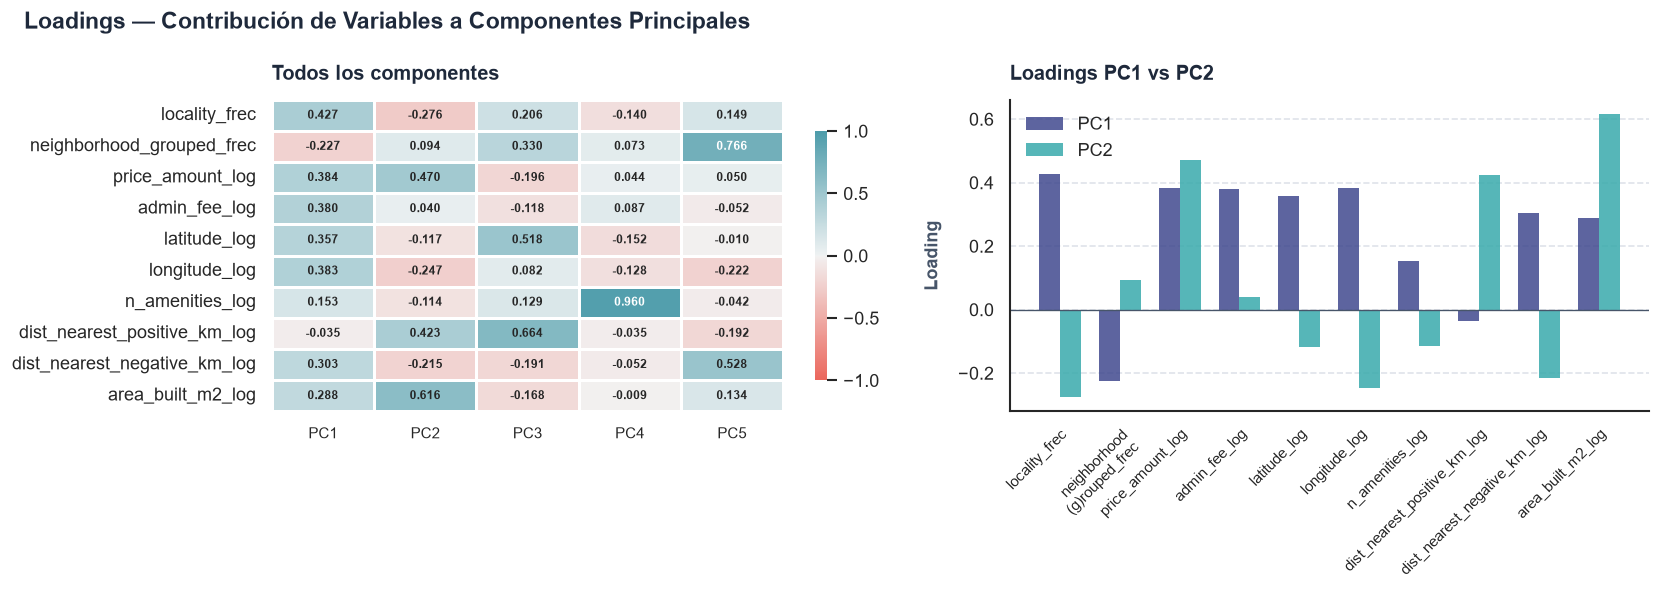

In [165]:
out = plot_loadings(pca_org_trans_5, df_features_pca_std.columns)

In [166]:
df_rec_org_trans = pca_org_trans_5.inverse_transform(df_pca_5_trans)

In [167]:
mse_error_org_trans = np.mean((df_features_pca_std - df_rec_org_trans) ** 2)

print(f"Error de reconstrucción promedio (MSE): {mse_error_org_trans}")

Error de reconstrucción promedio (MSE): 0.171666715458133


In [168]:
# Error cuadrático por variable (columnas)
mse_por_variable = np.mean(
    (df_features_pca_std - df_rec_org_trans) ** 2, axis=0
)

# Si df_pca_std es un DataFrame, puedes presentarlo como Series
error_variables_trans = pd.Series(
    mse_por_variable, index=df_features_pca_std.columns
)
print("Error de reconstrucción por variable:")
display(error_variables_trans.sort_values())

Error de reconstrucción por variable:


n_amenities_log                 0.011658
price_amount_log                0.063577
area_built_m2_log               0.083891
locality_frec                   0.100124
latitude_log                    0.127192
dist_nearest_positive_km_log    0.144786
neighborhood_grouped_frec       0.173198
longitude_log                   0.286401
dist_nearest_negative_km_log    0.307785
admin_fee_log                   0.418053
dtype: float64

In [169]:
df_mse_global = pd.DataFrame(
    {
        "Modelo": ["Transformado (_trans)", "Original"],
        "MSE Global": [mse_error_org_trans, mse_error_org],
    }
)


df_trans_vars = error_variables_trans.to_frame(
    name="MSE_Transformado"
).reset_index()
df_trans_vars.columns = ["Variable_Trans", "MSE_Transformado"]

series_trans_clean = error_variables_trans.copy()
series_trans_clean.index = series_trans_clean.index.str.replace("_log", "")

# Crear DataFrame consolidado y calcular la diferencia
df_comparacion_alineada = pd.DataFrame(
    {"MSE_Original": error_variables, "MSE_Transformado": series_trans_clean}
)

df_comparacion_alineada["Diferencia (Trans - Org)"] = (
    df_comparacion_alineada["MSE_Transformado"]
    - df_comparacion_alineada["MSE_Original"]
)

print("=== MSE GLOBAL ===")
display(df_mse_global)

print("\n=== COMPARACIÓN POR VARIABLE ===")
display(df_comparacion_alineada)

=== MSE GLOBAL ===


,Modelo,MSE Global
0,Transformado (_trans),0.171667
1,Original,0.172385



=== COMPARACIÓN POR VARIABLE ===


,MSE_Original,MSE_Transformado,Diferencia (Trans - Org)
admin_fee,0.343141,0.418053,0.074913
area_built_m2,0.165302,0.083891,-0.081411
dist_nearest_negative_km,0.365683,0.307785,-0.057898
dist_nearest_positive_km,0.165147,0.144786,-0.020361
latitude,0.117106,0.127192,0.010086
locality_frec,0.095071,0.100124,0.005053
longitude,0.303854,0.286401,-0.017452
n_amenities,0.036212,0.011658,-0.024553
neighborhood_grouped_frec,0.039802,0.173198,0.133396
price_amount,0.092532,0.063577,-0.028954


La col `Transformado` corresponde a la run en la que se usaron las variables sesgadas transformadas con log.

### Conclusión
A pesar de lo que se esperaba, el PCA que no transformó las variables antes de ajustarse fue marginalmente mejor (0.18 MSE vs 0.17 MSE). Esto muy posiblemente se deba a cómo se transformó la longitud, lo cual pudo sesgar el procedimiento al generar tal desplazamiento en esta; por lo tanto, en este experimento rindió mejor (marginalmente) el PCA que usa las variables originales estandarizadas.

## Excluyendo `price_amount` (lin reg)

### Usando `price_amount` (target)

In [170]:
PCA(n_components=3 if 3 > 4 else 5)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",5
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [171]:
def auto_pca(df, cols, n_comp=None, interpret=False, metrics=False):
    df_pca_std = StandardScaler().fit_transform(df[cols].copy())
    pca = PCA(n_components=n_comp)
    df_transformed = pca.fit_transform(df_pca_std)
    _ = plot_scree(pca)
    if interpret:
        _ = plot_loadings(pca, df_pca_std.columns)
    if metrics:
        print("=" * 90, "\n")
        df_rec = pca.inverse_transform(df_transformed)
        mse_error = np.mean((df_pca_std - df_rec) ** 2)

        print(f"Error de reconstrucción promedio (MSE): {mse_error}")

        mse_por_variable = np.mean((df_pca_std - df_rec) ** 2, axis=0)

        # Si df_pca_std es un DataFrame, puedes presentarlo como Series
        error_variables_trans = pd.Series(
            mse_por_variable, index=df_pca_std.columns
        )
        print("Error de reconstrucción por variable:")
        display(error_variables_trans.sort_values())

    return df_transformed

In [172]:
target = "price_amount"
numeric_pca_cols_lin = numeric_pca_cols.copy()
numeric_pca_cols_lin.remove(target)

print(numeric_pca_cols_lin)

['admin_fee', 'latitude', 'longitude', 'locality_frec', 'n_amenities', 'neighborhood_grouped_frec', 'dist_nearest_positive_km', 'dist_nearest_negative_km', 'area_built_m2']


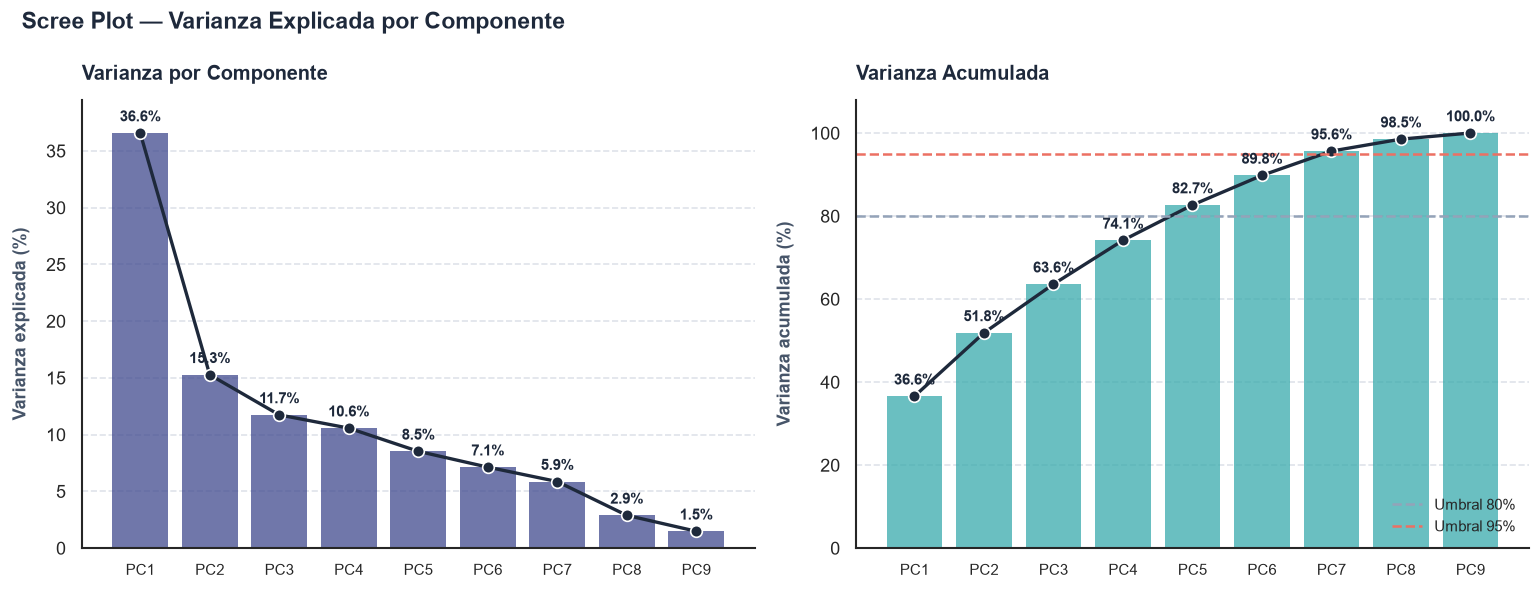

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



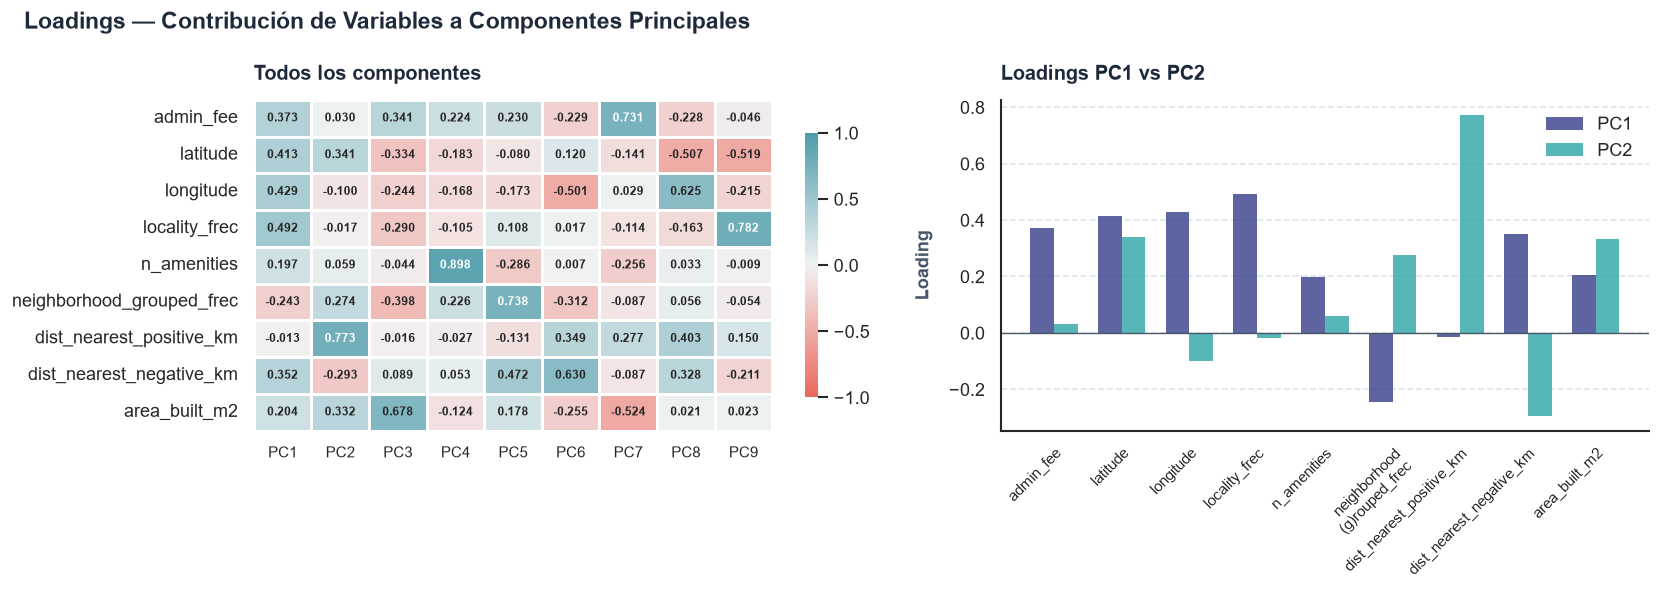


Error de reconstrucción promedio (MSE): 9.438379205559938e-31
Error de reconstrucción por variable:


admin_fee                    1.832054e-31
dist_nearest_positive_km     2.353172e-31
area_built_m2                3.911163e-31
dist_nearest_negative_km     5.905737e-31
longitude                    6.118726e-31
neighborhood_grouped_frec    1.005905e-30
n_amenities                  1.038454e-30
locality_frec                1.103116e-30
latitude                     3.334981e-30
dtype: float64

In [173]:
df_features_test = auto_pca(
    df[numeric_pca_cols_lin].copy(),
    numeric_pca_cols_lin,
    interpret=True,
    metrics=True,
)

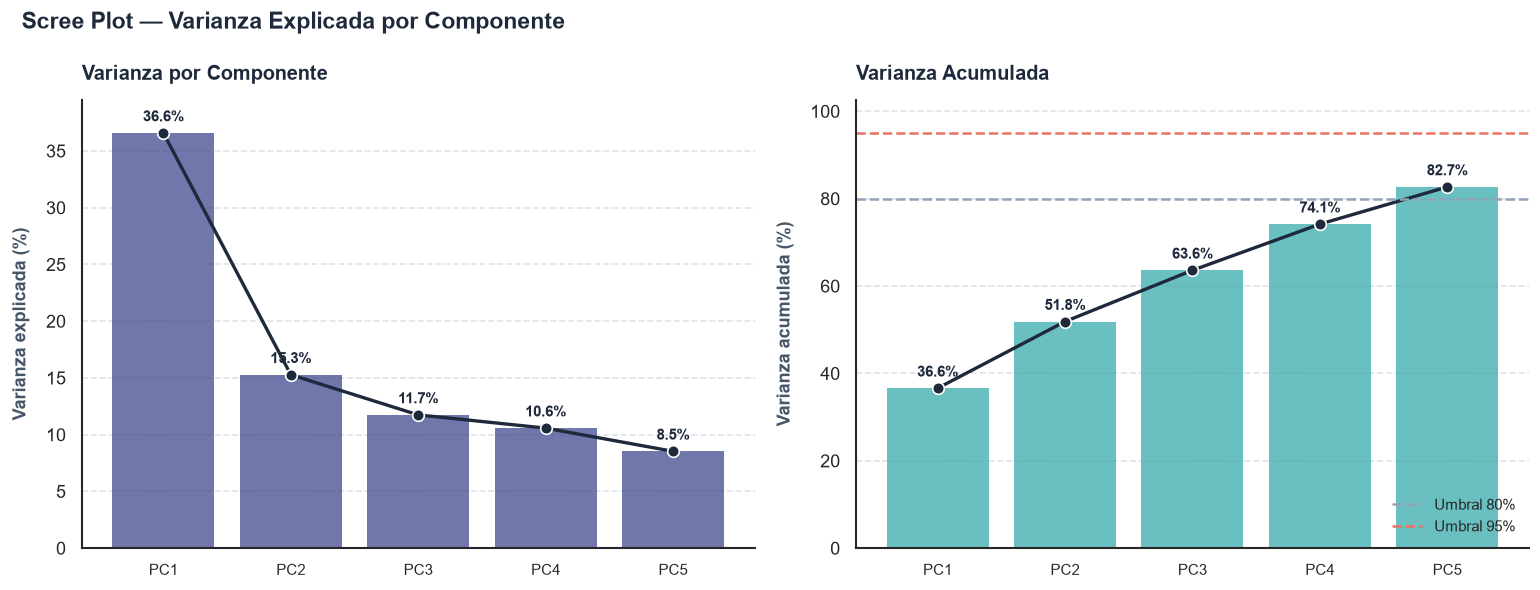

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



In [174]:
df_features_lin = auto_pca(
    df[numeric_pca_cols_lin].copy(), numeric_pca_cols_lin, 5
)

In [175]:
df_features_lin

,pca0,pca1,pca2,pca3,pca4
0,1.027434,-0.066215,-0.576024,0.541327,0.896024
1,-1.727004,0.872264,-0.121196,-0.461242,-0.174428
2,1.349995,-0.336778,-1.443348,0.344923,0.261629
3,0.948910,-0.267572,-1.634934,0.977433,-0.191790
4,1.650377,-1.593181,-0.054473,0.379774,-0.747824
...,...,...,...,...,...
20437,-2.353120,0.454966,0.272861,0.587875,-0.304201
20438,-1.333553,0.208306,-0.098686,-0.025674,0.565556
20439,-1.366145,-0.209615,-0.173153,1.849920,-0.366678
20440,0.193309,0.235575,-1.621840,-1.321949,0.848401


In [176]:
df_features_lin.shape[0] == df.shape[0]

True

In [177]:
X = sm.add_constant(df_features_lin)
y = df[target]

model_1 = sm.OLS(y, X).fit()

In [178]:
df_linreg_1 = pd.concat([X, y], axis=1)
df_linreg_1.drop(columns=["const"], inplace=True)

In [179]:
df_linreg_1

,pca0,pca1,pca2,pca3,pca4,price_amount
0,1.027434,-0.066215,-0.576024,0.541327,0.896024,8.800000e+08
1,-1.727004,0.872264,-0.121196,-0.461242,-0.174428,6.500000e+08
2,1.349995,-0.336778,-1.443348,0.344923,0.261629,6.250000e+08
3,0.948910,-0.267572,-1.634934,0.977433,-0.191790,4.700000e+08
4,1.650377,-1.593181,-0.054473,0.379774,-0.747824,1.170000e+09
...,...,...,...,...,...,...
20437,-2.353120,0.454966,0.272861,0.587875,-0.304201,5.799000e+08
20438,-1.333553,0.208306,-0.098686,-0.025674,0.565556,6.000000e+08
20439,-1.366145,-0.209615,-0.173153,1.849920,-0.366678,6.500000e+08
20440,0.193309,0.235575,-1.621840,-1.321949,0.848401,1.870000e+08


In [180]:
X

,const,pca0,pca1,pca2,pca3,pca4
0,1.0,1.027434,-0.066215,-0.576024,0.541327,0.896024
1,1.0,-1.727004,0.872264,-0.121196,-0.461242,-0.174428
2,1.0,1.349995,-0.336778,-1.443348,0.344923,0.261629
3,1.0,0.948910,-0.267572,-1.634934,0.977433,-0.191790
4,1.0,1.650377,-1.593181,-0.054473,0.379774,-0.747824
...,...,...,...,...,...,...
20437,1.0,-2.353120,0.454966,0.272861,0.587875,-0.304201
20438,1.0,-1.333553,0.208306,-0.098686,-0.025674,0.565556
20439,1.0,-1.366145,-0.209615,-0.173153,1.849920,-0.366678
20440,1.0,0.193309,0.235575,-1.621840,-1.321949,0.848401


In [181]:
vif_table(df_linreg_1, "price_amount", [f"pca{i}" for i in range(5)])

,Variable,VIF,descartada,alto
0,pca1,1.0,None,False
1,pca3,1.0,None,False
2,pca2,1.0,None,False
3,pca4,1.0,None,False
4,pca0,1.0,None,False


Gracias a la ortogonalidad de las componentes, el VIF de todas ellas es 1. Luego no hay redundancia en las características.

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,922592927.421143,2577397.974247,357.955169,0.000000,917541021.008404,927644833.833882
pca0,223639492.017298,1420645.481219,157.421042,0.000000,220854913.116984,226424070.917611
pca1,153942590.482628,2198663.042212,70.016454,0.000000,149633034.863595,158252146.101661
pca2,379301297.155263,2508458.935831,151.208892,0.000000,374384516.778061,384218077.532466
pca3,27169564.224021,2643146.353790,10.279251,0.000000,21988785.722625,32350342.725417
pca4,135672441.565806,2943175.104234,46.097305,0.000000,129903582.688963,141441300.442648


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,922592927.421143,2577397.974247,357.955169,0.000000,917541021.008404,927644833.833882
pca0,223639492.017298,1420645.481219,157.421042,0.000000,220854913.116984,226424070.917611
pca1,153942590.482628,2198663.042212,70.016454,0.000000,149633034.863595,158252146.101661
pca2,379301297.155263,2508458.935831,151.208892,0.000000,374384516.778061,384218077.532466
pca3,27169564.224021,2643146.353790,10.279251,0.000000,21988785.722625,32350342.725417
pca4,135672441.565806,2943175.104234,46.097305,0.000000,129903582.688963,141441300.442648


R**2: 0.7282968609830124
R**2 ajustado: 0.7282303843880288
F global: 10955.69
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 368,504,821.75


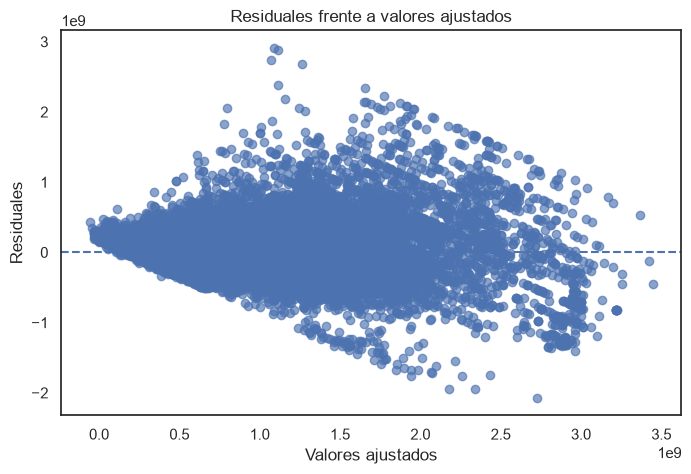

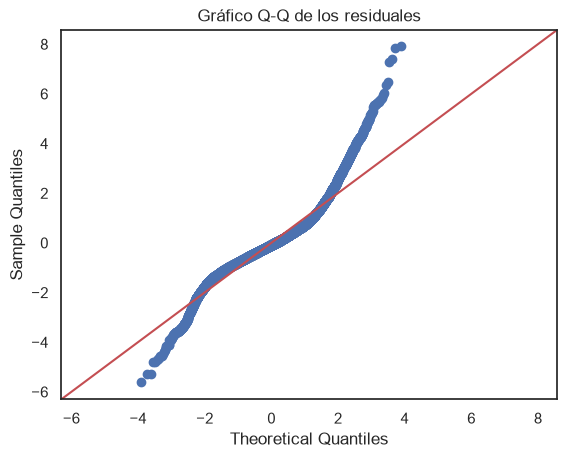

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,24061.96461,0.0,normalidad
1,Breusch-Pagan,2905.79724,0.0,homocedasticidad
2,Ramsey RESET,65396.68241,0.0,forma funcional adecuada
3,Durbin-Watson,1.92045,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.9204. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 1114
Observaciones con alto leverage (hat > 0.001): 1444
Observaciones influyentes (Cook D > 0.000): 1413


In [182]:
diagnosticador_modelo_1 = DiagnosticoOLS(model_1)
diagnosticador_modelo_1.reporte_completo()

### Usando `log_price_amount` (target)

In [183]:
X = sm.add_constant(df_features_lin)
y = np.log(df[target])

model_2 = sm.OLS(y, X).fit()

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.002877,7078.820463,0.000000,20.363532,20.374812
pca0,0.251831,0.001586,158.778665,0.000000,0.248722,0.254940
pca1,0.117803,0.002455,47.991860,0.000000,0.112992,0.122615
pca2,0.384420,0.002801,137.267429,0.000000,0.378930,0.389909
pca3,0.009502,0.002951,3.220004,0.001284,0.003718,0.015286
pca4,0.105257,0.003286,32.033422,0.000000,0.098816,0.111697


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.002877,7078.820463,0.000000,20.363532,20.374812
pca0,0.251831,0.001586,158.778665,0.000000,0.248722,0.254940
pca1,0.117803,0.002455,47.991860,0.000000,0.112992,0.122615
pca2,0.384420,0.002801,137.267429,0.000000,0.378930,0.389909
pca3,0.009502,0.002951,3.220004,0.001284,0.003718,0.015286
pca4,0.105257,0.003286,32.033422,0.000000,0.098816,0.111697


R**2: 0.6987117798669045
R**2 ajustado: 0.6986380648003226
F global: 9478.55
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.41


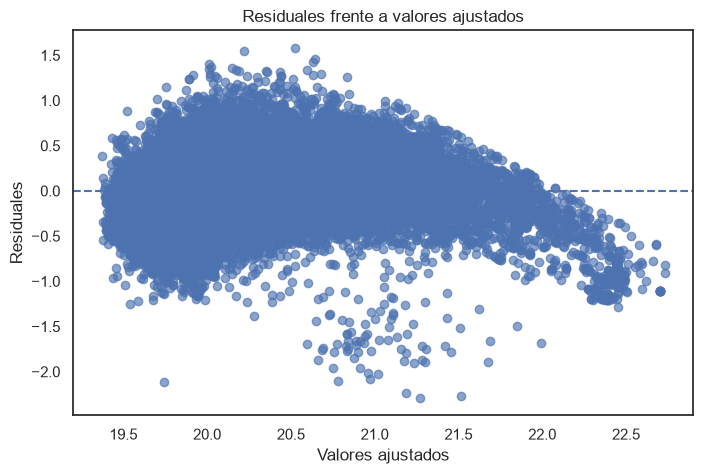

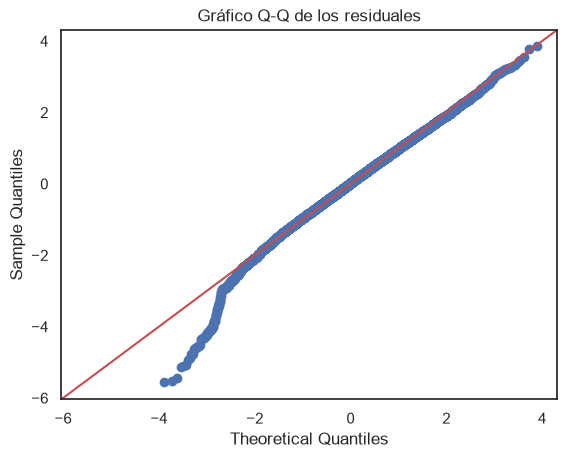

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,711.35992,0.0,normalidad
1,Breusch-Pagan,1266.25924,0.0,homocedasticidad
2,Ramsey RESET,3884.03086,0.0,forma funcional adecuada
3,Durbin-Watson,1.85513,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.8551. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 907
Observaciones con alto leverage (hat > 0.001): 1444
Observaciones influyentes (Cook D > 0.000): 970


In [184]:
diagnosticador_modelo_2 = DiagnosticoOLS(model_2)
diagnosticador_modelo_2.reporte_completo()

### Usando log log

In [185]:
log_feats = list(df_features_pca.columns)
log_feats.remove("price_amount_log")
print(log_feats)

['locality_frec', 'neighborhood_grouped_frec', 'admin_fee_log', 'latitude_log', 'longitude_log', 'n_amenities_log', 'dist_nearest_positive_km_log', 'dist_nearest_negative_km_log', 'area_built_m2_log']


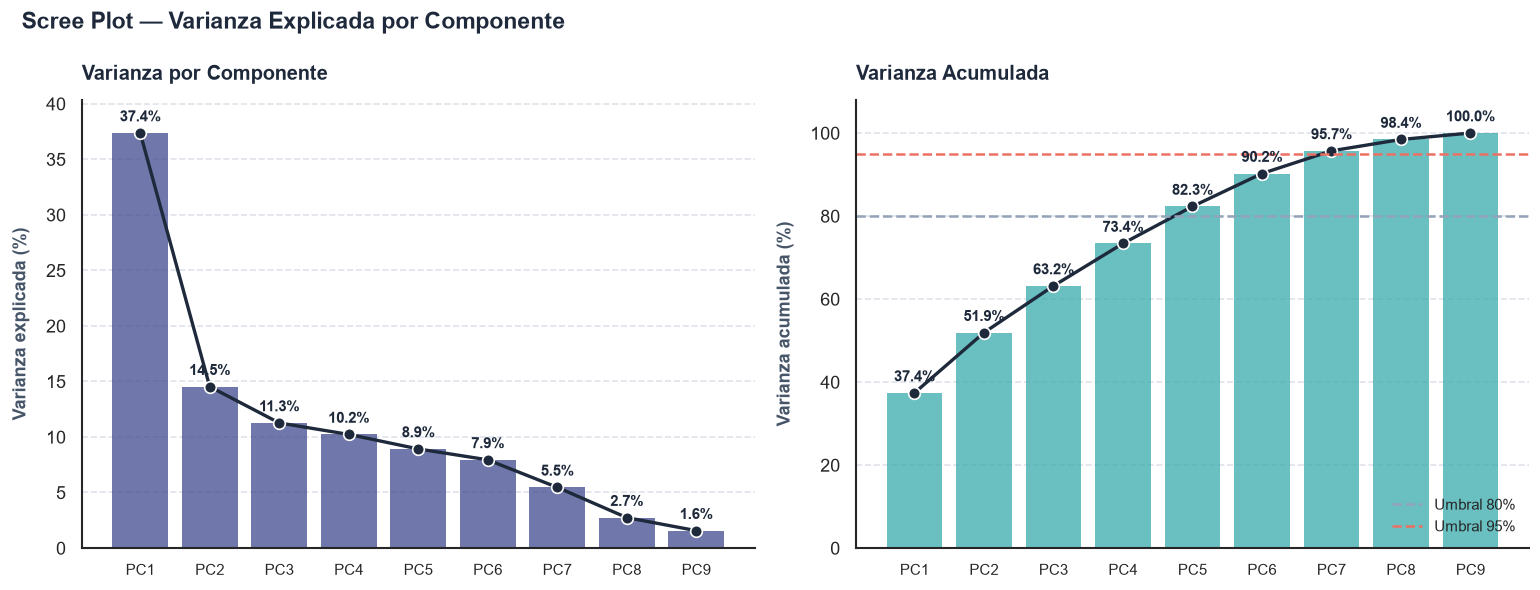

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



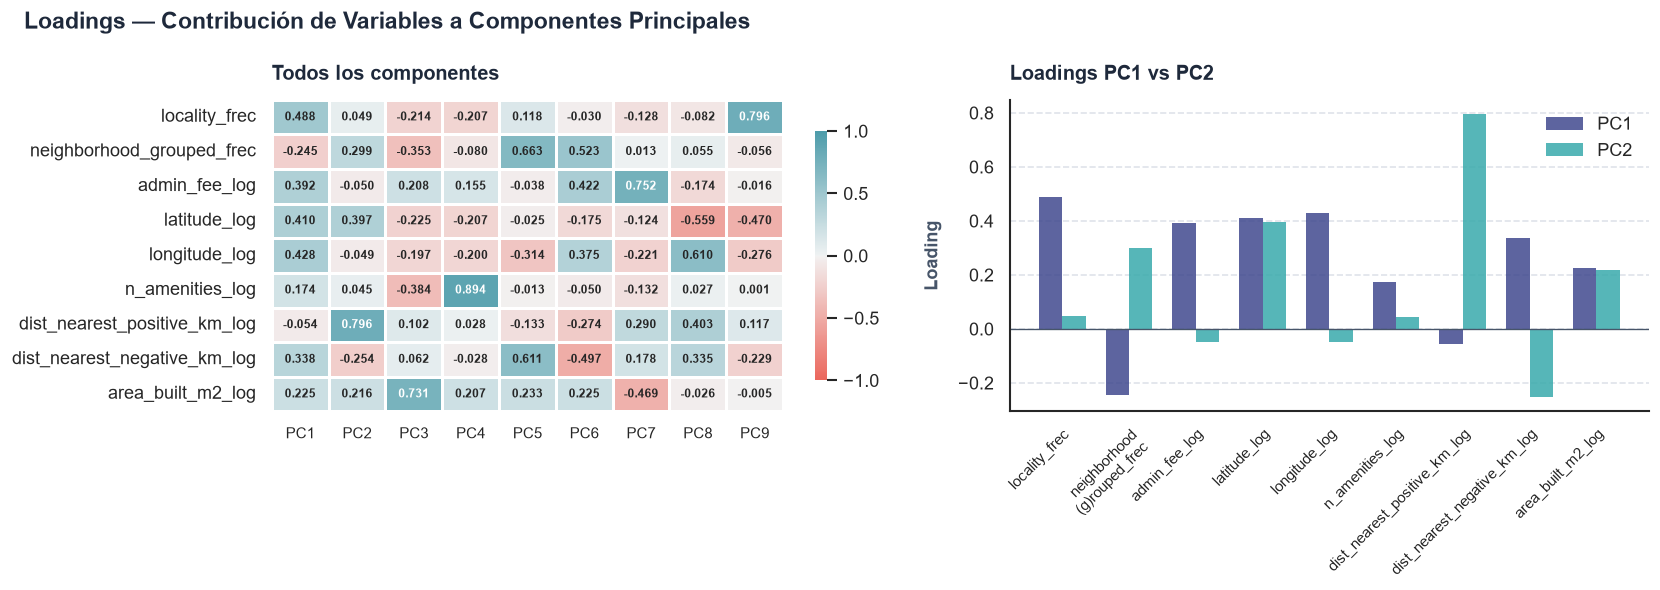

In [186]:
df_features_lin_log_test = auto_pca(
    df_features_pca.copy(), log_feats, interpret=True
)

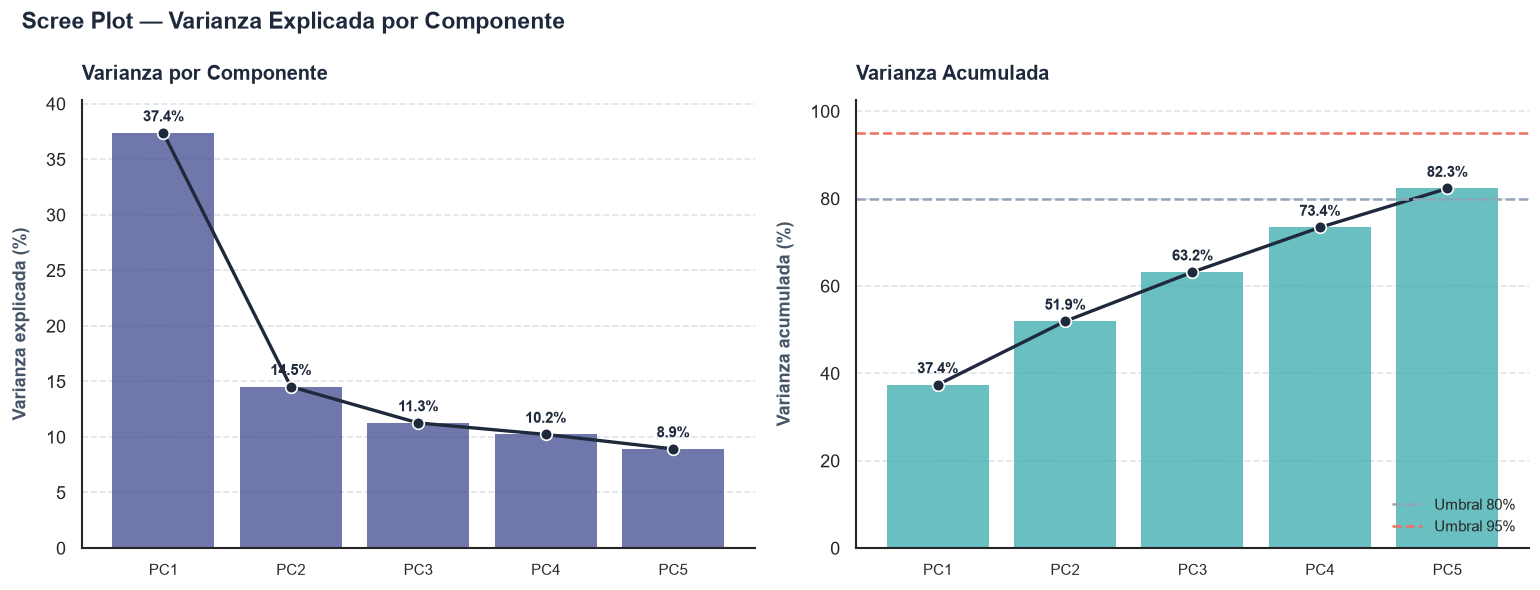

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



In [187]:
df_features_lin_log = auto_pca(df_features_pca.copy(), log_feats, n_comp=5)

In [188]:
df_features_lin_log

,pca0,pca1,pca2,pca3,pca4
0,1.233989,0.279932,-0.363680,0.405215,1.107311
1,-1.533802,1.057437,0.409713,0.019952,-0.432502
2,1.670047,-0.326472,-1.246666,0.002076,0.572101
3,1.057529,-0.121379,-1.835189,0.174578,0.044799
4,1.790141,-1.536117,-0.369198,0.461956,-0.505115
...,...,...,...,...,...
20437,-2.486550,0.552621,0.207271,1.082889,-0.290580
20438,-1.255700,0.466587,0.117800,0.281826,0.912352
20439,-1.239552,-0.204668,-0.459575,1.359568,0.068942
20440,-0.218148,0.599485,-0.712760,-3.135407,0.757197


In [189]:
X = sm.add_constant(df_features_lin_log)
y = df_features_pca["price_amount_log"]

In [190]:
df_lin_log_log = pd.concat([X, y], axis=1)

In [191]:
df_lin_log_log

,const,pca0,pca1,pca2,pca3,pca4,price_amount_log
0,1.0,1.233989,0.279932,-0.363680,0.405215,1.107311,20.595432
1,1.0,-1.533802,1.057437,0.409713,0.019952,-0.432502,20.292483
2,1.0,1.670047,-0.326472,-1.246666,0.002076,0.572101,20.253262
3,1.0,1.057529,-0.121379,-1.835189,0.174578,0.044799,19.968243
4,1.0,1.790141,-1.536117,-0.369198,0.461956,-0.505115,20.880270
...,...,...,...,...,...,...,...
20437,1.0,-2.486550,0.552621,0.207271,1.082889,-0.290580,20.178366
20438,1.0,-1.255700,0.466587,0.117800,0.281826,0.912352,20.212440
20439,1.0,-1.239552,-0.204668,-0.459575,1.359568,0.068942,20.292483
20440,1.0,-0.218148,0.599485,-0.712760,-3.135407,0.757197,19.046619


In [192]:
vif_table(df_lin_log_log, "price_amount_log")

Aviso: 1 columna(s) de varianza cero, sin VIF definido: const


,Variable,VIF,descartada,alto
0,pca0,1.0,None,False
1,pca1,1.0,None,False
2,pca3,1.0,None,False
3,pca4,1.0,None,False
4,pca2,1.0,None,False
5,const,NaN,varianza cero,False


In [193]:
model_3 = sm.OLS(y, X).fit()

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.002534,8036.943261,0.000000,20.364204,20.374140
pca0,0.248720,0.001382,179.956952,0.000000,0.246011,0.251429
pca1,0.081957,0.002217,36.975237,0.000000,0.077613,0.086302
pca2,0.427807,0.002517,169.933839,0.000000,0.422872,0.432741
pca3,0.156078,0.002642,59.080470,0.000000,0.150900,0.161256
pca4,0.083766,0.002829,29.613974,0.000000,0.078222,0.089310


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.002534,8036.943261,0.000000,20.364204,20.374140
pca0,0.248720,0.001382,179.956952,0.000000,0.246011,0.251429
pca1,0.081957,0.002217,36.975237,0.000000,0.077613,0.086302
pca2,0.427807,0.002517,169.933839,0.000000,0.422872,0.432741
pca3,0.156078,0.002642,59.080470,0.000000,0.150900,0.161256
pca4,0.083766,0.002829,29.613974,0.000000,0.078222,0.089310


R**2: 0.7662658640231237
R**2 ajustado: 0.766208677162687
F global: 13399.33
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.36


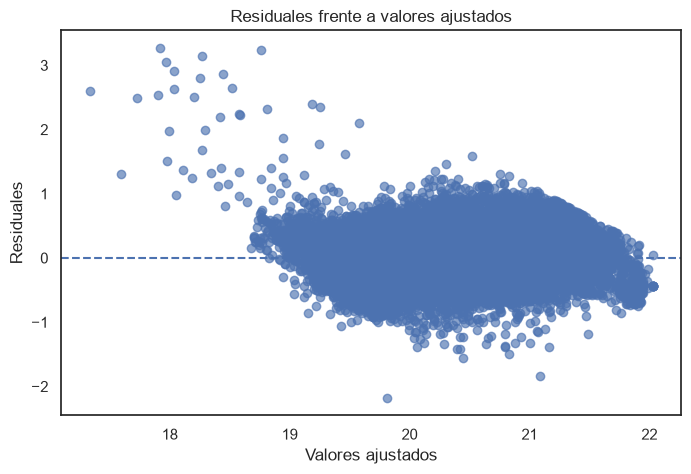

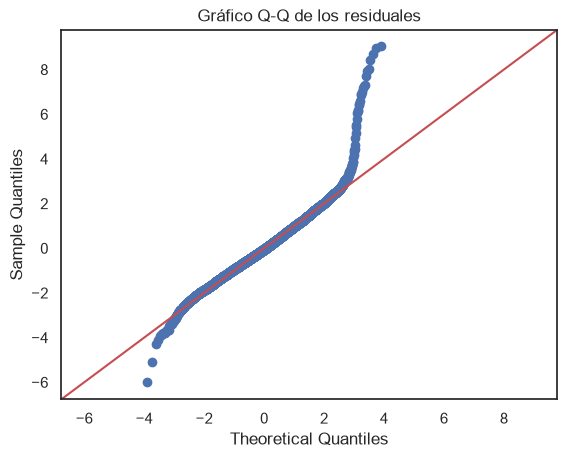

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,9587.94168,0.0,normalidad
1,Breusch-Pagan,695.93870,0.0,homocedasticidad
2,Ramsey RESET,97.89745,0.0,forma funcional adecuada
3,Durbin-Watson,1.87239,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.8724. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 808
Observaciones con alto leverage (hat > 0.001): 960
Observaciones influyentes (Cook D > 0.000): 963


In [194]:
diagnosticador_modelo_3 = DiagnosticoOLS(model_3)
diagnosticador_modelo_3.reporte_completo()

### Usando log log + variables categóricas

Se reutiliza `df_lin_log_log` (componentes de PCA sobre las log-variables y `price_amount_log`) y se le añaden las variables categóricas (codificadas) que quedaron por fuera de PCA: `stratum` y `age_bracket_code` como códigos ordinales, las banderas binarias y las dummies de estado de construcción, ciudad, tipo de publicador y tipo de inmueble.

In [195]:
cat_prefixes = (
    "construction_state_grouped_",
    "city_",
    "publisher_type_",
    "property_type_",
)
cat_cols = [
    "stratum",
    "age_bracket_code",
    "Trans Publico cerc",
    "Zona Residencial",
    *[c for c in df.columns if c.startswith(cat_prefixes)],
]
df_lin_log_log_cat = pd.concat([df_lin_log_log, df[cat_cols]], axis=1)
df_lin_log_log_cat

,const,pca0,pca1,pca2,pca3,pca4,price_amount_log,stratum,age_bracket_code,Trans Publico cerc,...,city_Chía,city_Soacha,city_Zipaquirá,publisher_type_desarrollador,publisher_type_inmobiliaria,property_type_apartaestudio,property_type_casa,property_type_casa_campestre,property_type_finca,property_type_habitacion
0,1.0,1.233989,0.279932,-0.363680,0.405215,1.107311,20.595432,4.0,4.0,1,...,0,0,0,0,0,0,1,0,0,0
1,1.0,-1.533802,1.057437,0.409713,0.019952,-0.432502,20.292483,3.0,5.0,1,...,0,0,0,0,0,0,1,0,0,0
2,1.0,1.670047,-0.326472,-1.246666,0.002076,0.572101,20.253262,5.0,4.0,1,...,0,0,0,0,0,0,1,0,0,0
3,1.0,1.057529,-0.121379,-1.835189,0.174578,0.044799,19.968243,4.0,2.0,1,...,0,0,0,0,0,0,0,0,0,0
4,1.0,1.790141,-1.536117,-0.369198,0.461956,-0.505115,20.880270,6.0,1.0,1,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20437,1.0,-2.486550,0.552621,0.207271,1.082889,-0.290580,20.178366,3.0,4.0,1,...,0,0,0,0,1,0,1,0,0,0
20438,1.0,-1.255700,0.466587,0.117800,0.281826,0.912352,20.212440,3.0,5.0,1,...,0,0,0,0,1,0,1,0,0,0
20439,1.0,-1.239552,-0.204668,-0.459575,1.359568,0.068942,20.292483,4.0,4.0,0,...,0,0,0,0,1,0,0,0,0,0
20440,1.0,-0.218148,0.599485,-0.712760,-3.135407,0.757197,19.046619,2.0,3.0,0,...,0,0,0,0,1,0,0,0,0,0


In [196]:
vif_table(df_lin_log_log_cat, "price_amount_log")

Aviso: 1 columna(s) de varianza cero, sin VIF definido: const


,Variable,VIF,descartada,alto
0,stratum,2.841043,None,False
1,pca0,2.725373,None,False
2,publisher_type_desarrollador,2.433592,None,False
3,construction_state_grouped_Otros,2.358603,None,False
4,pca2,2.190312,None,False
5,Trans Publico cerc,2.021613,None,False
6,property_type_casa,1.921367,None,False
7,Zona Residencial,1.825921,None,False
8,pca3,1.784971,None,False
9,pca1,1.359851,None,False


In [197]:
X = df_lin_log_log_cat.drop(columns=["price_amount_log"])
y = df_lin_log_log_cat["price_amount_log"]

model_4 = sm.OLS(y, X).fit()

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,19.470653,0.018664,1043.235047,0.000000,19.434071,19.507236
pca0,0.147185,0.002046,71.938317,0.000000,0.143174,0.151195
pca1,0.070233,0.002318,30.301977,0.000000,0.065690,0.074776
pca2,0.338666,0.003341,101.368720,0.000000,0.332118,0.345215
pca3,0.133158,0.003165,42.073397,0.000000,0.126955,0.139362
pca4,0.065030,0.002690,24.174310,0.000000,0.059757,0.070302
stratum,0.189624,0.003133,60.515628,0.000000,0.183483,0.195766
age_bracket_code,-0.010940,0.001788,-6.118515,0.000000,-0.014445,-0.007435
Trans Publico cerc,-0.010708,0.006875,-1.557403,0.119390,-0.024184,0.002769
Zona Residencial,-0.012167,0.006302,-1.930532,0.053555,-0.024520,0.000186


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,19.470653,0.018664,1043.235047,0.000000,19.434071,19.507236
pca0,0.147185,0.002046,71.938317,0.000000,0.143174,0.151195
pca1,0.070233,0.002318,30.301977,0.000000,0.065690,0.074776
pca2,0.338666,0.003341,101.368720,0.000000,0.332118,0.345215
pca3,0.133158,0.003165,42.073397,0.000000,0.126955,0.139362
pca4,0.065030,0.002690,24.174310,0.000000,0.059757,0.070302
stratum,0.189624,0.003133,60.515628,0.000000,0.183483,0.195766
age_bracket_code,-0.010940,0.001788,-6.118515,0.000000,-0.014445,-0.007435
construction_state_grouped_A estrenar,0.081098,0.022746,3.565317,0.000364,0.036513,0.125683
construction_state_grouped_Excelente estado,0.035312,0.008396,4.205560,0.000026,0.018854,0.051770


R**2: 0.8122266861603373
R**2 ajustado: 0.8120151675875921
F global: 3839.98
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.32


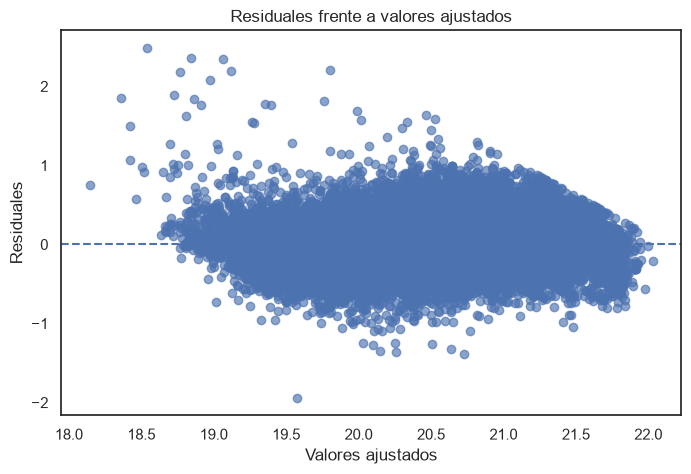

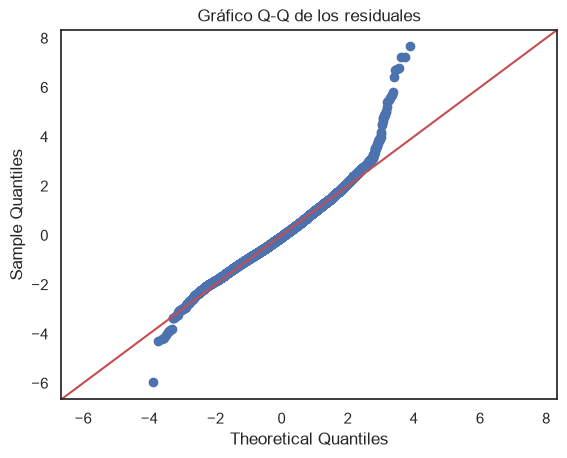

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,2697.31565,0.0,normalidad
1,Breusch-Pagan,613.50967,0.0,homocedasticidad
2,Ramsey RESET,32.28134,0.0,forma funcional adecuada
3,Durbin-Watson,1.90333,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.9033. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 864
Observaciones con alto leverage (hat > 0.002): 1136
Observaciones influyentes (Cook D > 0.000): 649


In [198]:
diagnosticador_modelo_4 = DiagnosticoOLS(model_4)
diagnosticador_modelo_4.reporte_completo()

Note que, en general, los modelos preprocesados con PCA fueron peores que los ajustados con las variables sin transformar en `notebooks/model_OLS.ipynb`. Esto ocurre ya que PCA solo extrae las componentes que mejor explican la variabilidad del propio conjunto de predictores $X$, y esos componentes no son necesariamente aquellos (direcciones) que mejor describen o predicen $y$.

# Aplicar PPCA

Se retomarán los 2 paradigmas que se tenían antes: con las variables sin transformar y transformando las variables (con log).

In [199]:
def auto_ppca(df, cols, n_comp=None, verboose=False, scree=False):
    scaler = StandardScaler()
    df_pca_std = scaler.fit_transform(df[cols].copy())
    X = np.asarray(df_pca_std)

    ppca = PCA(n_components=n_comp)
    ppca.fit(X)

    sigma_sq = ppca.noise_variance_

    # Matriz de cargas probabilísticas W: W = Q_k * sqrt(Lambda_k - sigma^2 I)
    components = ppca.components_  # (k, p)
    eigenvalues = ppca.explained_variance_  # (k,)

    # Ajuste probabilístico sobre las cargas
    W = components.T @ np.diag(np.sqrt(np.maximum(0, eigenvalues - sigma_sq)))

    p, k = W.shape
    C_ppca = W @ W.T + sigma_sq * np.eye(p)

    # Media posterior E[z|x] = M^-1 W^T x, con M = W^T W + sigma^2 I_k (k x k)
    M = W.T @ W + sigma_sq * np.eye(k)
    Z_ppca = np.linalg.solve(M, W.T @ X.T).T  # (n, k)

    # Reconstrucción del modelo en escala estandarizada: x_hat = W E[z|x]
    df_rec_std = Z_ppca @ W.T  # (n, p)

    mse_por_variable = np.mean((X - df_rec_std) ** 2, axis=0)
    mse_error = mse_por_variable.mean()
    error_variables_trans = pd.Series(mse_por_variable, index=cols)

    df_transformed = pd.DataFrame(
        Z_ppca,
        index=df_pca_std.index,
        columns=[f"ppca{i}" for i in range(k)],
    )

    if verboose:
        print("=" * 90 + "\n")
        # Varianza residual del ruido (sigma^2)
        print(f"Varianza residual del ruido (σ² residual): {sigma_sq}")
        print(f"Error de reconstrucción promedio (MSE): {mse_error}")
        print("\nError de reconstrucción por variable:")
        display(error_variables_trans.sort_values())
        _ = plot_ppca_matrices(W, C_ppca, cols)
        if scree:
            _ = plot_scree(ppca)

    return (
        df_transformed,
        ppca,
        {"mse_total": mse_error, "mse_por_variable": mse_por_variable},
    )

## Usando las variables originales

In [200]:
len(numeric_pca_cols)

10

In [201]:
df_pca = df[numeric_pca_cols].copy()
df_pca_std = StandardScaler().fit_transform(df_pca)


Varianza residual del ruido (σ² residual): 0.0
Error de reconstrucción promedio (MSE): 6.371183874412643e-32

Error de reconstrucción por variable:


n_amenities                  4.563881e-32
dist_nearest_positive_km     5.080235e-32
dist_nearest_negative_km     5.537741e-32
latitude                     5.576611e-32
neighborhood_grouped_frec    5.847622e-32
area_built_m2                6.062256e-32
locality_frec                7.083352e-32
admin_fee                    7.112550e-32
price_amount                 7.676317e-32
longitude                    9.171274e-32
dtype: float64

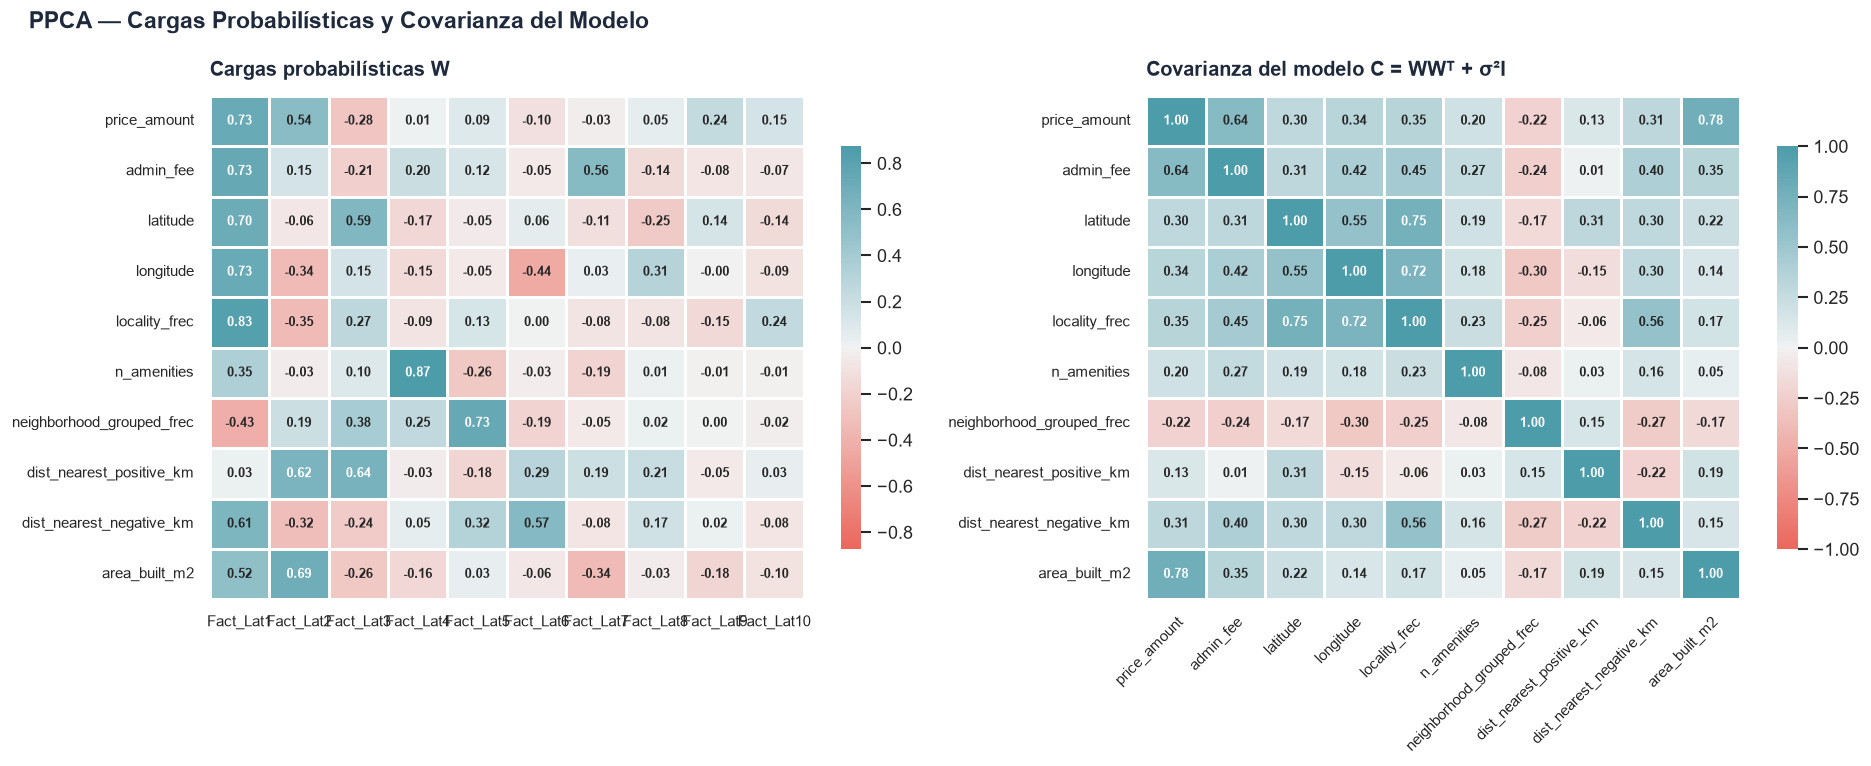

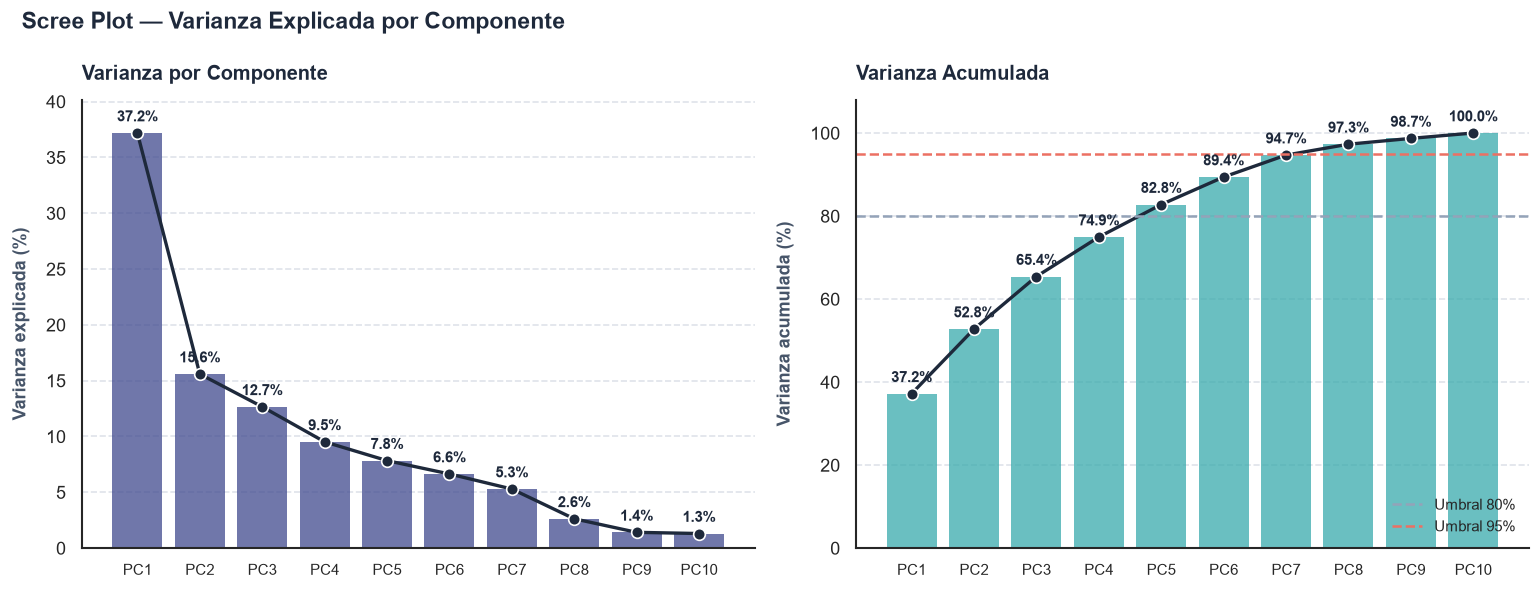

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



In [202]:
primer_ppca = auto_ppca(df, numeric_pca_cols, verboose=True, scree=True)

Note que las direcciones de PCA se mantienen y, ya que PPCA parte de ellas, luego se puede usar el mismo criterio que se usó en secciones anteriores para escoger cuántas componentes usar, por lo que en esta oportunidad se usan 5 componentes de nuevo.


Varianza residual del ruido (σ² residual): 0.34478672981298886
Error de reconstrucción promedio (MSE): 0.22028133783592999

Error de reconstrucción por variable:


locality_frec                0.116632
price_amount                 0.118802
n_amenities                  0.151450
latitude                     0.151792
neighborhood_grouped_frec    0.165618
area_built_m2                0.199336
dist_nearest_positive_km     0.221327
longitude                    0.319292
admin_fee                    0.360388
dist_nearest_negative_km     0.398176
dtype: float64

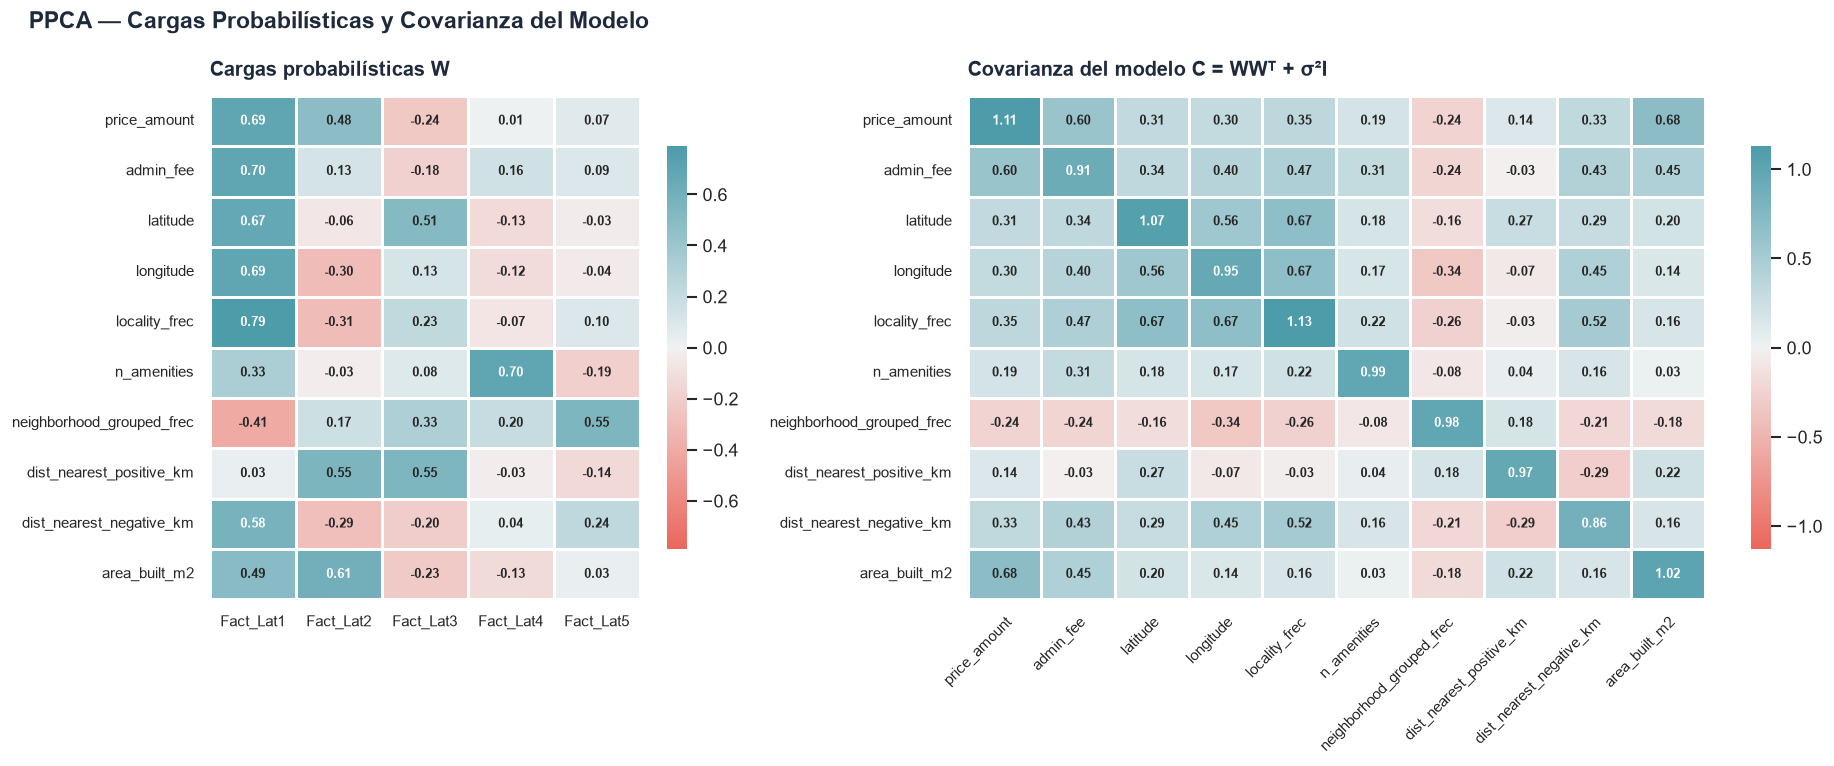

In [203]:
df_ppca_5, ppca1, ppca_1_metrics = auto_ppca(
    df, numeric_pca_cols, 5, verboose=True
)

Vea que la varianza del residuo corresponde a $\approx 0.348$; esto es el ruido que se obtuvo al descartar las 5 componentes que fueron descartadas, pues esa información ahora actúa como ruido que el modelo no es capaz de explicar. Note cómo la diagonal es diferente de 1 a pesar de basarse en datos estandarizados (en PCA originalmente sería diagonal 1 al ser una matriz de corr); eso indica que la estructura de $\hat{C}$ considera la variabilidad que el modelo no explica.

Adicionalmente, la matriz $\hat{W}$ cambia respecto a la $Q_k$ de PCA, pues esta ahora incluye el ruido del residuo que no explica el modelo probabilístico; luego se tiene que:

- El primer factor actúa como un descriptor de la escala del inmueble, tal que será más grande mientras el inmueble sea más caro, grande y con más amenidades; además, también se ve potenciado si la distancia a un `landmark` negativo es alta. **Luego describe casas costosas, grandes, cerca de varias amenidades, que además están al nororiente de la ciudad (latitud y longitud más grandes o cercanas a 0 desde la escala neg)**.

- El segundo factor describe principalmente la geolocalización del inmueble: será grande si este está lejos de un `landmark` positivo y más cerca de uno negativo; además, se ve potenciado al tener longitudes altas, es decir, se ve potenciado por viviendas que quedan más al oriente; además, se ve potenciado por localidades frecuentes en la muestra (se codificaron con Frequency Encoding y eran Suba y Usaquén); por lo tanto, describe **viviendas más al oriente con una cercanía mayor a un punto negativo que a uno positivo, pero que mantienen un buen tamaño**.

- El tercero describe viviendas pequeñas que están lejos de los landmark pos y cerca de los neg; adicionalmente, son más económicas y poseen administraciones bajas. Describe inmuebles modestos, pero que a su vez son más económicos.

- El cuarto netamente describe cuántas amenidades reportó un inmueble.

- El quinto principalmente describe el vecindario del inmueble.





## Con las log variables

In [204]:
df_features_pca

,locality_frec,neighborhood_grouped_frec,price_amount_log,admin_fee_log,latitude_log,longitude_log,n_amenities_log,dist_nearest_positive_km_log,dist_nearest_negative_km_log,area_built_m2_log
0,0.275462,0.690441,20.595432,13.508987,1.742506,0.159165,3.258097,0.823247,1.520372,5.081404
1,0.060219,0.690441,20.292483,12.510332,1.732621,0.149932,2.197225,1.107403,0.620868,5.039547
2,0.310195,0.690441,20.253262,13.374679,1.751633,0.176250,3.332205,0.373202,1.194848,4.795791
3,0.310195,0.690441,19.968243,13.235694,1.744240,0.181765,3.583519,0.627599,1.078531,4.043051
4,0.310195,0.025536,20.880270,13.676198,1.737979,0.172599,3.367296,0.499634,1.494334,4.387922
...,...,...,...,...,...,...,...,...,...,...
20437,0.033607,0.690441,20.178366,11.777003,1.736329,0.094413,3.135494,0.652266,0.215624,5.298317
20438,0.037912,0.690441,20.212440,11.870544,1.737392,0.127121,2.639057,0.960360,1.360498,4.907790
20439,0.069905,0.690441,20.292483,12.925845,1.727853,0.141361,3.688879,0.789747,0.919585,4.503580
20440,0.275462,0.690441,19.046619,11.896245,1.750232,0.146191,0.000000,0.959794,1.443612,3.760493



Varianza residual del ruido (σ² residual): 0.0
Error de reconstrucción promedio (MSE): 4.922188933173526e-32

Error de reconstrucción por variable:


area_built_m2_log               4.026252e-32
price_amount_log                4.246561e-32
admin_fee_log                   4.503444e-32
n_amenities_log                 4.534991e-32
longitude_log                   4.764801e-32
latitude_log                    4.827409e-32
neighborhood_grouped_frec       4.845181e-32
locality_frec                   5.338774e-32
dist_nearest_negative_km_log    5.980613e-32
dist_nearest_positive_km_log    6.153866e-32
dtype: float64

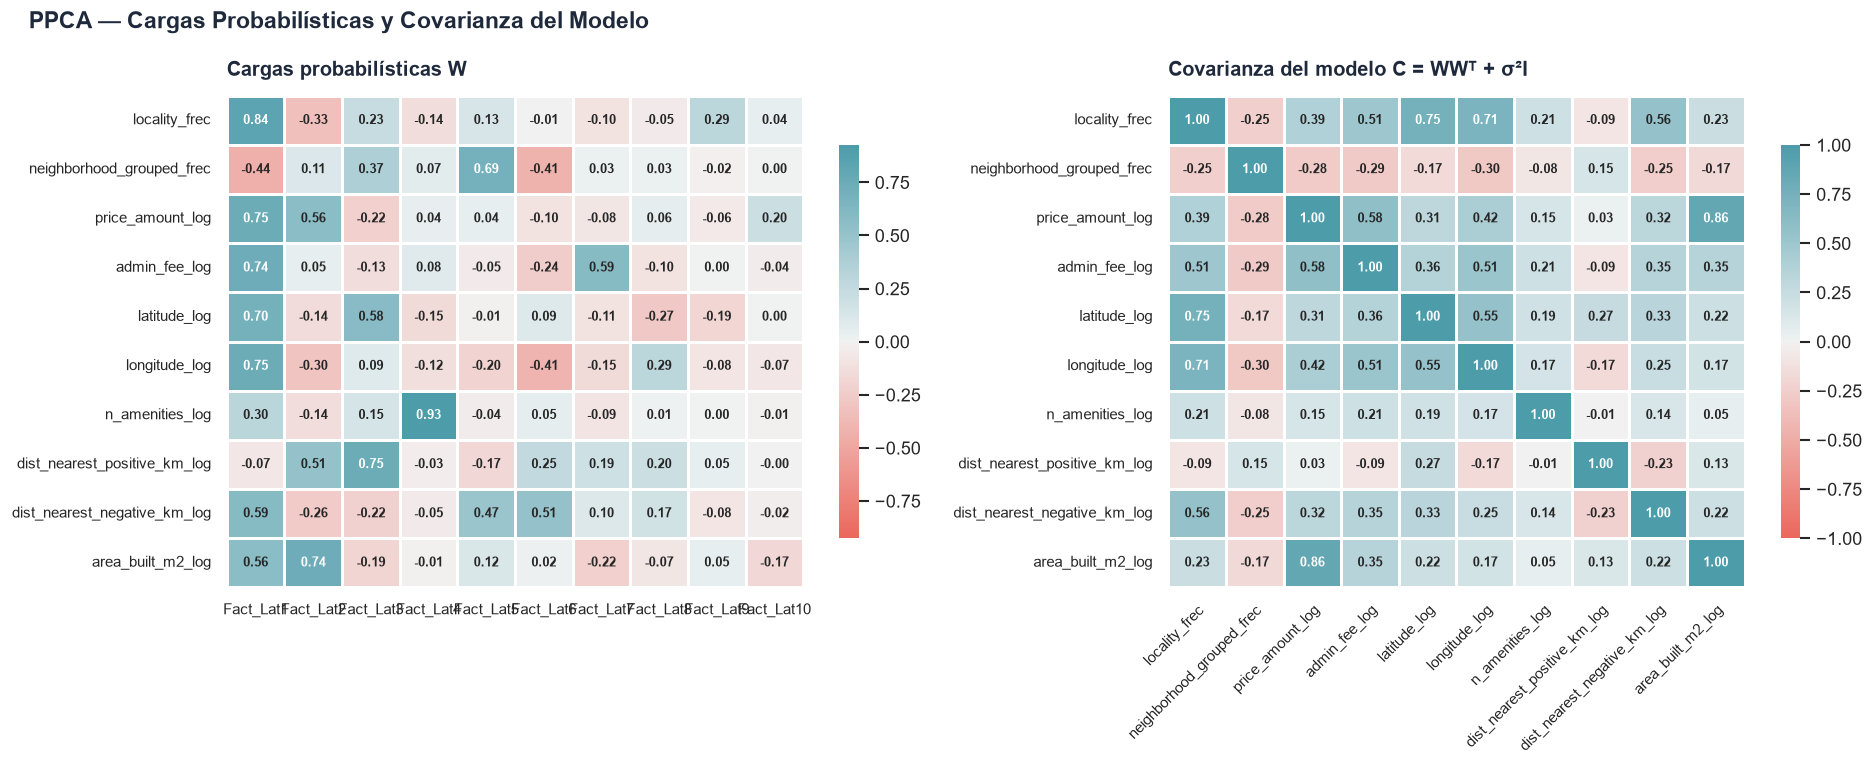

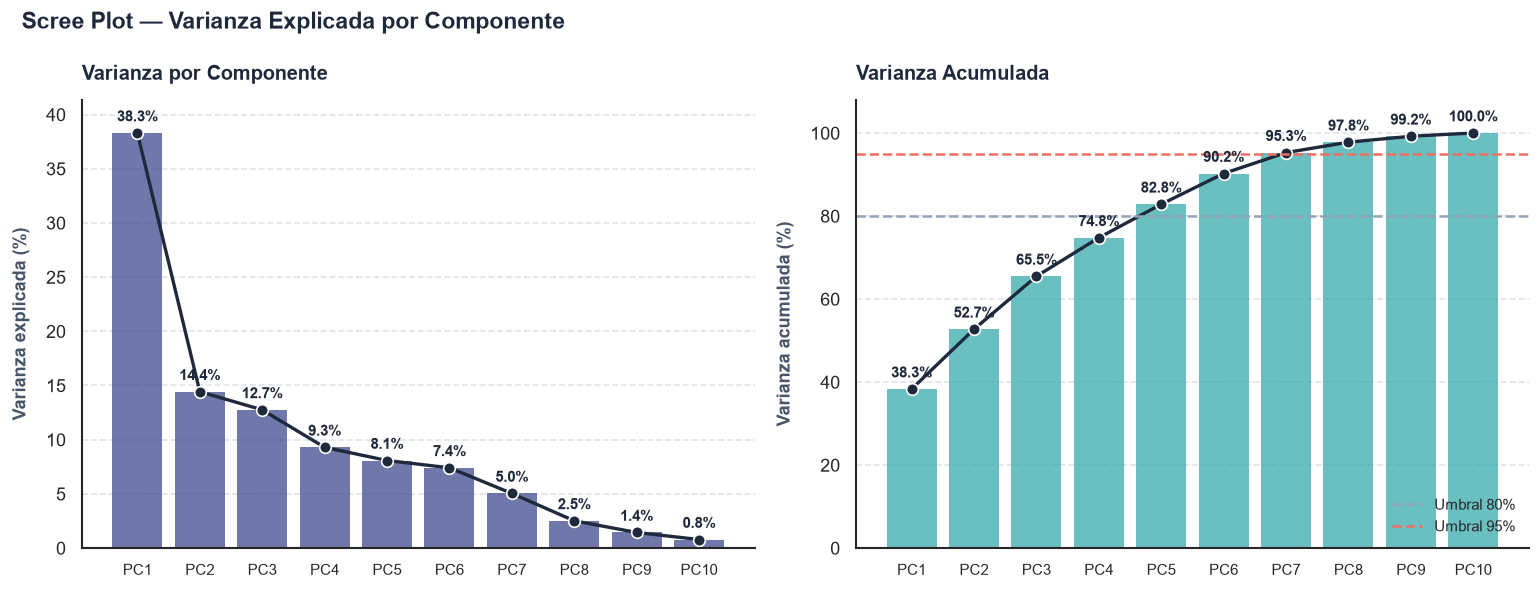

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



In [205]:
_, _, _ = auto_ppca(
    df_features_pca, df_features_pca.columns, verboose=True, scree=True
)

Note que de nuevo se puede heredar el criterio de 5 componentes (en este caso factores) usado en PCA.


Varianza residual del ruido (σ² residual): 0.34335022722911324
Error de reconstrucción promedio (MSE): 0.21944841010606347

Error de reconstrucción por variable:


price_amount_log                0.090318
locality_frec                   0.121651
area_built_m2_log               0.122682
n_amenities_log                 0.132250
latitude_log                    0.160004
dist_nearest_positive_km_log    0.205727
neighborhood_grouped_frec       0.271940
longitude_log                   0.305785
dist_nearest_negative_km_log    0.358872
admin_fee_log                   0.425255
dtype: float64

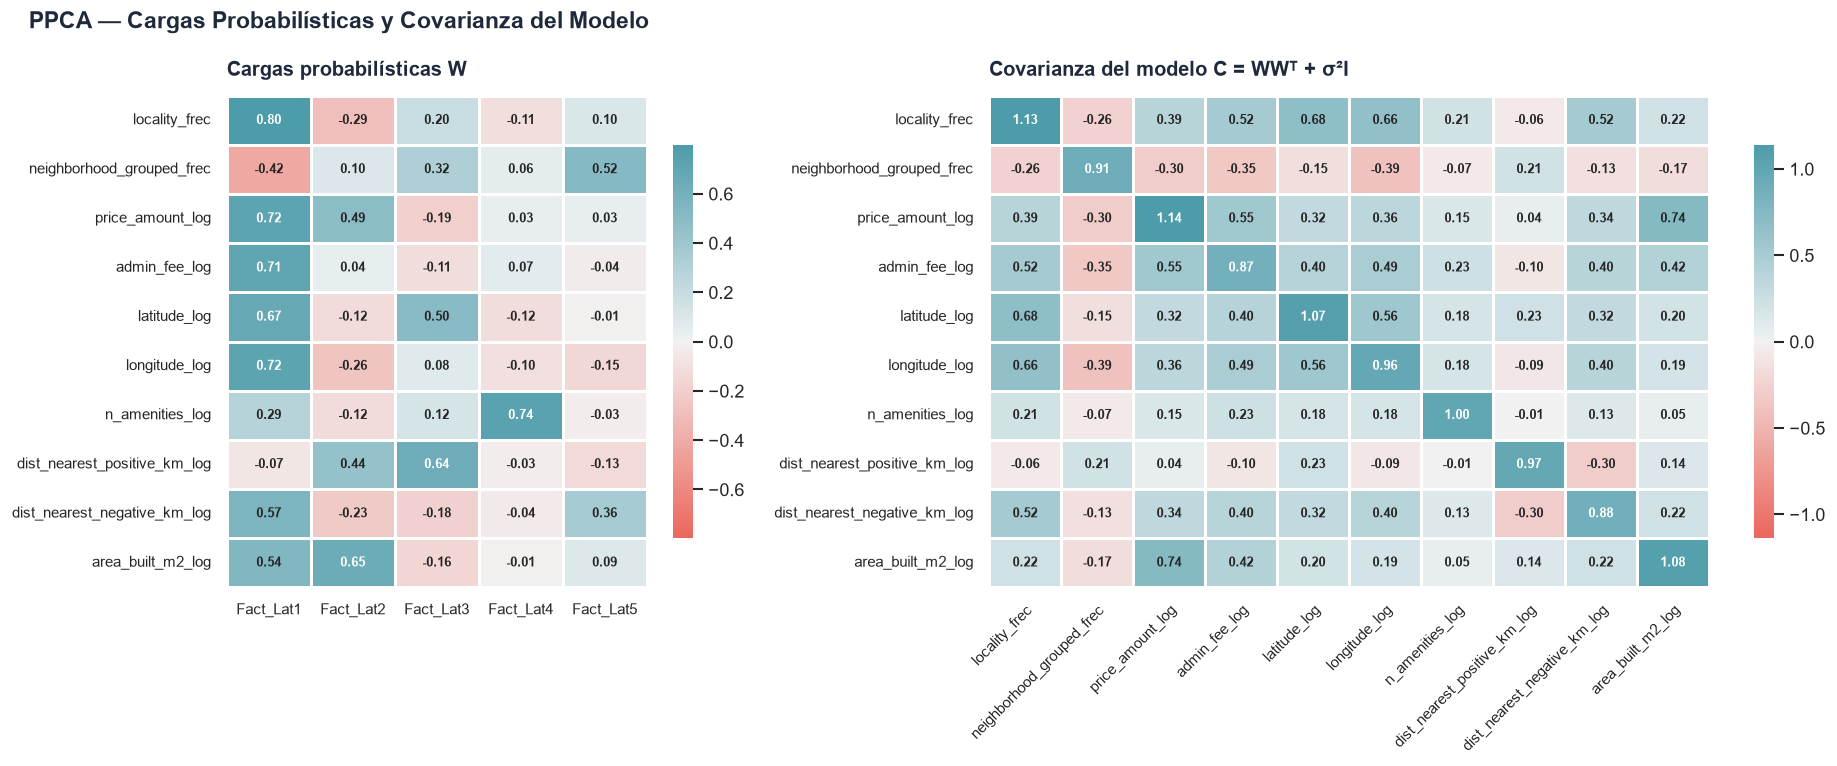

In [206]:
df_ppca_log_5, ppca_log, ppca_log_metrics = auto_ppca(
    df_features_pca, df_features_pca.columns, 5, verboose=True
)

La interpretación es similar en los factores latentes, solo que con números ligeramente distintos, esto debido a que se usaron las log_variables en lugar de estas sin transformar, aunque este modelo y el PCA que también usó esas variables tienen un serio problema, que es que las coordenadas se tuvieron que desplazar y comprimir, por lo que se sacrifica interpretabilidad.

> Nota: habrá notado que cuando se tienen todos los factores latentes sin descartar, la variabilidad del residuo es 0. Numéricamente, porque al no quedar componentes ese promedio se toma como 0; conceptualmente, eso indica que toda la variabilidad está siendo explicada por el modelo y, al no descartar direcciones con info, no hay nada que se comprima en esa variabilidad en ruido de los datos sin explicar, porque se descartó lo que los explica.

## Comparación PCA vs PPCA (conjunto completo)

In [207]:
# MSE de reconstrucción de los cuatro modelos sobre el conjunto completo
# (5 componentes): PCA y PPCA, con variables originales y con log.
df_mse_global_modelos = pd.DataFrame(
    {
        "Método": ["PCA", "PCA", "PPCA", "PPCA"],
        "Variables": ["Originales", "Log", "Originales", "Log"],
        "MSE Global": [
            mse_error_org,
            mse_error_org_trans,
            ppca_1_metrics["mse_total"],
            ppca_log_metrics["mse_total"],
        ],
        # Solo el modelo probabilístico tiene término de ruido
        "σ² residual": [
            np.nan,
            np.nan,
            ppca1.noise_variance_,
            ppca_log.noise_variance_,
        ],
    }
)

# Los MSE por variable de PPCA son arrays: se indexan con los nombres
# originales (sin el sufijo _log) para alinearlos con los de PCA
ppca_vars = pd.Series(
    ppca_1_metrics["mse_por_variable"], index=numeric_pca_cols
)
ppca_log_vars = pd.Series(
    ppca_log_metrics["mse_por_variable"],
    index=df_features_pca.columns.str.replace("_log", ""),
)

df_comparacion_modelos = pd.DataFrame(
    {
        "PCA_Original": error_variables,
        "PCA_Log": series_trans_clean,
        "PPCA_Original": ppca_vars,
        "PPCA_Log": ppca_log_vars,
    }
)
# PCA y PPCA reconstruyen con la misma proyección: se redondea para que
# el ruido numérico (~1e-16) no decida el empate
df_comparacion_modelos["Mejor modelo"] = df_comparacion_modelos.round(
    10
).idxmin(axis=1)

print("=== MSE GLOBAL ===")
display(df_mse_global_modelos)

print("\n=== COMPARACIÓN POR VARIABLE ===")
display(df_comparacion_modelos)

=== MSE GLOBAL ===


,Método,Variables,MSE Global,σ² residual
0,PCA,Originales,0.172385,NaN
1,PCA,Log,0.171667,NaN
2,PPCA,Originales,0.220281,0.344787
3,PPCA,Log,0.219448,0.343350



=== COMPARACIÓN POR VARIABLE ===


,PCA_Original,PCA_Log,PPCA_Original,PPCA_Log,Mejor modelo
admin_fee,0.343141,0.418053,0.360388,0.425255,PCA_Original
area_built_m2,0.165302,0.083891,0.199336,0.122682,PCA_Log
dist_nearest_negative_km,0.365683,0.307785,0.398176,0.358872,PCA_Log
dist_nearest_positive_km,0.165147,0.144786,0.221327,0.205727,PCA_Log
latitude,0.117106,0.127192,0.151792,0.160004,PCA_Original
locality_frec,0.095071,0.100124,0.116632,0.121651,PCA_Original
longitude,0.303854,0.286401,0.319292,0.305785,PCA_Log
n_amenities,0.036212,0.011658,0.151450,0.132250,PCA_Log
neighborhood_grouped_frec,0.039802,0.173198,0.165618,0.271940,PCA_Original
price_amount,0.092532,0.063577,0.118802,0.090318,PCA_Log


Note que los MSE globales son similares en todos los modelos (del mismo tipo), esto ya que todos describen los mismos datos (o transformaciones de estos) con el mismo número de componentes. Aún más interesante es ver que los errores de reconstrucción de PPCA por lo general son mayores; esto se debe a que PPCA también considera la variabilidad que no pueden explicar sus componentes ($W$ y $M$ contienen un término de variabilidad residual $\sigma^2$). A pesar de que en un principio PCA podría parecer ganarle a PPCA por eso, este último incorpora la capacidad generativa de datos, que además permite saber cómo se van a distribuir las observaciones y permite interpretar las columnas de W como factores latentes no observados para comprender mejor la estructura de los datos. Además, PPCA tiene en cuenta la variabilidad que no puede explicar y la toma como un factor de ruido, por lo que tambien se puede descomponer en efectos.

Luego, cada modelo tiene su uso: PCA para describir direcciones de manera determinística y probar el preprocesamiento de datos, y PPCA para estimar probabilidades, reconocer cómo se distribuyen los datos y generar un espacio latente que permite interpretar factores latentes como estructura no vista, de la cual se puede estimar cuánto es señal y cuánto ruido.